<a href="https://colab.research.google.com/github/owlmt/QML/blob/main/01_Network_Intrusion_Detection/QSVM_IntrusionDetection_Gouveia2020.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Autoencoder + quantum-kernel SVM for network intrusion detection: Gouveia and Correia (2020) step by step

This notebook re-implements, runs and checks the method of

> Arnaldo Gouveia and Miguel Correia, "Towards Quantum-Enhanced Machine Learning for Network Intrusion Detection",
> *2020 IEEE 19th International Symposium on Network Computing and Applications (NCA)*, IEEE, 2020.
> DOI 10.1109/NCA51143.2020.9306691

The paper publishes no code. Everything below is written from its six-page description.

**What the notebook does.** It downloads the two datasets of the paper (NSL-KDD and UNSW-NB15), draws the paper's tiny
samples (100 training and 50 test connections for NSL-KDD, 150 and 50 for UNSW-NB15), turns every connection into numbers in
[0, 1], squeezes it through an **autoencoder** (the paper used the R package Ruta; here a one-hidden-layer autoencoder in
scikit-learn with the same four activation functions) to obtain a 2-dimensional latent code, normalises the code, and
classifies normal against malicious traffic with a **quantum-kernel SVM**: the kernel is
$K(x,z)=|\langle\Phi(x)|\Phi(z)\rangle|^2$ of the Havlicek ZZ feature map, built in Qiskit with a circuit depth of 2, 3, 4
and 5 (the paper's Table I). The same samples are classified by classical SVMs and random forests on identical inputs, and the
paper's "classical SVM over the entire dataset" (Table II) is rerun on tens of thousands of connections. The paper's kernel
matrices (Figs. 9 and 10), accuracy-versus-depth plot (Fig. 8) and autoencoder codes (Figs. 3 to 7) are redrawn, and the last
section puts every number of the paper next to ours with a verdict per claim.

**How to run it.** Open in Colab (badge above), choose a CPU runtime and use *Runtime -> Run all*. The first cell installs
pinned Qiskit packages (restart the session if Colab asks). With `FAST_MODE = True` (default) the notebook runs end to end in
roughly 10 to 25 minutes on a (shared) CPU; the committed outputs are those of this FAST run (3 draws, 4,000-row autoencoder pool
and big-SVM pools, Qiskit cross-check at depths 2 and 5; 21.5 min of cell time measured on a heavily loaded laptop).
`FAST_MODE = False` is the full budget: 10 draws, 20,000-row autoencoder pool (100 epochs), 20,000 / 10,000 connections for the
large classical SVM, extra latent sizes of 3 and 4 qubits and the Qiskit cross-check at all four depths (not executed for this
publication; expect one to two hours on a CPU). Everything is simulated: the paper itself used the Qiskit simulator ("IBM QX in simulation mode"), so no IBM account
is needed.

**What you get at the end.** A table of accuracy / precision / recall / F1 (attack = positive class) for every depth, the
classical references, figures of the real connections coloured by their labels, the drawn feature-map circuits, and a
claim-by-claim comparison with the paper.

## The paper in one page

**Problem.** Flag network flows as normal or malicious (an anomaly-based NIDS) with a quantum-assisted unsupervised
representation plus a quantum kernel.

**Decision.** A support-vector machine whose kernel is computed on a quantum computer (Havlicek et al., Nature 2019, "method 2":
estimate the overlap of two feature-map states for every pair of training points, solve the SVM dual classically, estimate the
kernel again for each test point against the support vectors). Class labels: +1 / -1.

**Method.** (1) take flows, (2) numeric-encode and normalise into [0, 1], (3) **autoencoder** (R package Ruta `autoencode()`)
as the dimensionality reduction, tried with Linear, hyperbolic-tangent, ReLU and Sigmoid activations on NSL-KDD and with Sigmoid
on UNSW-NB15, (4) normalise the latent code, (5) Qiskit `QSVM()` on the simulator with a second-order Pauli-Z ("ZZ") feature map
whose **depth** is 2, 3, 4, 5 (Table I). The feature map is $U_\Phi(x)=\big(U_{\Phi(x)}H^{\otimes n}\big)^{\text{depth}}$ with
$U_{\Phi(x)}=\exp\big(i\sum_{S\subseteq[n]}\phi_S(x)\prod_{i\in S}Z_i\big)$ and $|S|\le 2$ (Eq. 4).

**Data.** NSL-KDD: 100 training and 50 test samples drawn from `KDDTrain+.arff`. UNSW-NB15: 150 training and 50 test samples
drawn from the NB15 training file. (The official test files were not used for testing "as the statistical distribution does
not match": the autoencoder was apparently fitted separately on each file.)

**Claims (all accuracies).**

| Table | NSL-KDD | UNSW-NB15 |
|---|---|---|
| QSVM, depth 2 / 3 / 4 / 5 (Table I) | 0.80 / 0.92 / 0.92 / 0.92 | 0.60 / 0.64 / 0.64 / 0.64 |
| classical liquidSVM "over the entire dataset" (Table II) | 0.93 | 0.75 |
| liquidSVM positive / negative validation error (Table II) | 0.136 / 0.019 | 0.132 / 0.383 |

Qualitative claims: accuracy rises with circuit depth then saturates (Fig. 8); the quantum SVM is "very close" to the classical
one on NSL-KDD (0.92 vs 0.93) and "somewhat lower" on UNSW-NB15 (0.64 vs 0.75); the kernel matrices of the best cases show clearer
blocks (Figs. 9 and 10); the result depends on the dataset; test and training codes must come from the same distribution; and
the conclusion that the numbers "hint at an advantage for the quantum processing".

### What follows the paper and what had to be chosen

| Item | Paper | This notebook |
|---|---|---|
| Data | NSL-KDD `KDDTrain+.arff`, UNSW-NB15 training file | `KDDTrain+.txt` (identical records, 125,973 rows, GitHub mirror) and the official UNSW-NB15 training partition (175,341 rows, Hugging Face parquet) |
| Samples | 100 / 50 (NSL-KDD), 150 / 50 (UNSW-NB15) | same sizes; random draw with the file's natural class mix (the paper does not say how it sampled), repeated for `N_RUNS` seeds |
| Numeric encoding | "non-numeric features encoded into numbers, normalised into [0, 1]" | ordinal codes for `protocol_type`/`service`/`flag` (`proto`/`service`/`state`), min-max to [0, 1] fitted on the unlabelled pool |
| Autoencoder | Ruta `autoencode()` (R / Keras), latent size not given, trained loss about 9.3 to 9.4 | scikit-learn `MLPRegressor` with one hidden layer = the latent code, activation identity / tanh / relu / logistic, latent size = number of qubits (2); `# CHOICE:` fitted on an unlabelled pool that contains none of the evaluation connections |
| Latent normalisation | "the data returned by `autoencode()` was normalised" | min-max to [0, 1] fitted on the 100 / 150 training codes, test codes clipped |
| Qubits | not stated | 2 (latent plots of the paper are two-dimensional); 3 and 4 as an extra in the full run |
| Feature map | Qiskit Aqua `QSVM()` with a ZZ map, "depth" 2 to 5 | `zz_feature_map(n, reps=depth, entanglement="full")` (the Aqua default is full entanglement; for 2 qubits linear and full coincide) |
| Angle scale | codes fed as they are | bandwidth 1 = "as published"; a bandwidth in {0.5, 1, 2, pi} and `C` in {1, 10, 100} are also tuned on a validation split of the training data only ("tuned") |
| Kernel / solver | Aqua `QSVM` (dual SVM, `C = 1`) | exact statevector kernel, `SVC(kernel="precomputed")`; asserted equal to Qiskit's `FidelityStatevectorKernel` / `QSVC` |
| Classical SVM | liquidSVM (automatic k-fold hyper-parameters) on the *entire* dataset after the autoencoder | (a) RBF-SVM on exactly the same small latent samples, defaults and tuned; (b) RBF-SVM tuned by 3-fold CV and trained on tens of thousands of connections (`BIG_TRAIN`), the closest analogue of Table II |
| Hardware | none (simulation) | none |
| Seeds | not reported | `SEED = 42`, runs use `SEED + run` |

## 0. Setup

In [1]:
# Versions tested with this notebook (October 2026). Colab already ships numpy, pandas, scikit-learn and matplotlib.
import importlib.util
IN_COLAB = importlib.util.find_spec("google.colab") is not None
_needed = ["qiskit", "qiskit_machine_learning", "qiskit_aer", "qiskit_ibm_runtime", "huggingface_hub", "pyarrow", "pylatexenc"]
if IN_COLAB or any(importlib.util.find_spec(m) is None for m in _needed):
    %pip install -q "qiskit==2.5.2" "qiskit-machine-learning==0.9.1" "qiskit-aer==0.17.2" "qiskit-ibm-runtime==0.50.0" pylatexenc huggingface_hub pyarrow
    print("Installed. If Colab asks you to restart the session, do so and run all cells again.")
else:
    print("Qiskit packages already present; skipping pip install.")

Qiskit packages already present; skipping pip install.


In [2]:
# ---------------- configuration ----------------
import math
FAST_MODE = True        # True: a few minutes (3 draws, small pools). False: 10 draws, larger pools, 3 and 4 qubits as an extra.
SEED = 42               # CHOICE: the paper reports no seed
IBM_TOKEN = ""          # the paper ran Qiskit in simulation; no hardware cell is needed, so this stays empty

# data (public mirrors; see Section 1)
DATA_DIR = "qc341_data"
LOCAL_NSL = ""          # optional: path to your own KDDTrain+.txt
LOCAL_UNSW = ""         # optional: path to your own UNSW-NB15 training partition (csv or parquet)

# the paper's sample sizes (Section IV-B)
DATASETS = ["NSL-KDD", "UNSW-NB15"]
N_TRAIN = {"NSL-KDD": 100, "UNSW-NB15": 150}
N_TEST = {"NSL-KDD": 50, "UNSW-NB15": 50}

# quantum model
DEPTHS = [2, 3, 4, 5]               # paper Table I: "circuit depth" = repetitions of the ZZ feature map
N_QUBITS = 2                        # CHOICE: latent size = number of qubits (the paper does not say; its latent plots are 2-D)
ENTANGLEMENT = "full"               # CHOICE: Qiskit Aqua default; identical to "linear" for 2 qubits
ACTIVATIONS = {"NSL-KDD": ["identity", "tanh", "relu", "logistic"],   # paper: Linear, Hyperbolic Tangent, ReLU, Sigmoid
               "UNSW-NB15": ["logistic"]}                              # paper: Sigmoid only
ACT_NAME = {"identity": "linear", "tanh": "tanh", "relu": "relu", "logistic": "sigmoid"}

# hyper-parameters tuned on an inner validation split of the TRAINING sample only
VAL_FRACTION = 0.25
BW_GRID = [1.0, 0.5, 2.0, math.pi]  # CHOICE: angle bandwidth candidates; 1.0 first = the paper's setting, pi = angles in [0, pi]
C_GRID = [1.0, 10.0, 100.0]         # CHOICE: SVM regularisation candidates; 1.0 first = Qiskit default
SVM_C_GRID = [1.0, 10.0, 100.0]     # classical RBF-SVM
SVM_G_GRID = [1.0, 4.0, 16.0, 64.0]
ALLFEAT_G_GRID = [0.1, 0.3, 1.0, 3.0]

if FAST_MODE:
    N_RUNS = 3              # repeated random draws of the paper's 100 / 50 (150 / 50) samples
    AE_POOL_N = 4000        # unlabelled rows the autoencoder is fitted on
    AE_MAX_ITER = 60
    BIG_TRAIN, BIG_TEST = 4000, 4000    # classical "entire dataset" SVM (Table II analogue)
    EXTRA_DIMS = []         # extra latent sizes (qubits) for the headline activation
    QISKIT_DEPTHS = [2, 5]  # depths at which the exact kernel is also computed with Qiskit's FidelityStatevectorKernel
else:
    N_RUNS = 10
    AE_POOL_N = 20000
    AE_MAX_ITER = 100
    BIG_TRAIN, BIG_TEST = 20000, 10000
    EXTRA_DIMS = [3, 4]
    QISKIT_DEPTHS = [2, 3, 4, 5]
SMALL_AE_ITER = 500         # epochs when an autoencoder is fitted on only 50 to 150 rows
TOL = 0.02                  # verdict tolerance: two accuracy points / 0.02 in the other metrics

In [3]:
import os
HF_TOKEN = os.environ.get("HF_TOKEN")
if HF_TOKEN is None:
    try:
        from google.colab import userdata          # Colab: Settings > Secrets > HF_TOKEN
        HF_TOKEN = userdata.get("HF_TOKEN")
    except Exception:
        HF_TOKEN = None
print("Hugging Face token available:", HF_TOKEN is not None, "(the UNSW-NB15 mirror is public; a token only helps with rate limits)")

Hugging Face token available: True (the UNSW-NB15 mirror is public; a token only helps with rate limits)


In [4]:
import os, time, json, warnings
os.environ["HF_HUB_DISABLE_PROGRESS_BARS"] = "1"
for _v in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS"):
    os.environ.setdefault(_v, "2")                   # CHOICE: keeps a shared machine responsive; harmless on Colab
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
import sklearn
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import MinMaxScaler
from sklearn.decomposition import PCA
from sklearn.neural_network import MLPRegressor
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay
import qiskit, qiskit_machine_learning
from qiskit import QuantumCircuit
from qiskit.circuit import ParameterVector
from qiskit.circuit.library import zz_feature_map
from qiskit.quantum_info import Statevector
from qiskit_machine_learning.kernels import FidelityStatevectorKernel
from qiskit_machine_learning.algorithms import QSVC
from qiskit_machine_learning.utils import algorithm_globals

warnings.filterwarnings("ignore")
algorithm_globals.random_seed = SEED
np.random.seed(SEED)
rng = np.random.default_rng(SEED)
os.makedirs(DATA_DIR, exist_ok=True)
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 40); pd.set_option("display.max_rows", 200)
NOTEBOOK_T0 = time.perf_counter()
def seconds_since(t0): return time.perf_counter() - t0
print("qiskit", qiskit.__version__, "| qiskit-machine-learning", qiskit_machine_learning.__version__,
      "| scikit-learn", sklearn.__version__, "| numpy", np.__version__, "| pandas", pd.__version__)
print("FAST_MODE =", FAST_MODE, "| runs:", N_RUNS, "| qubits:", N_QUBITS, "| depths:", DEPTHS)

qiskit 2.5.2 | qiskit-machine-learning 0.9.1 | scikit-learn 1.9.1 | numpy 2.5.4 | pandas 3.0.6
FAST_MODE = True | runs: 3 | qubits: 2 | depths: [2, 3, 4, 5]


## 1. The two datasets

**NSL-KDD** (Tavallaee et al., 2009) is the de-duplicated version of the KDD Cup 1999 intrusion data: one row per TCP/UDP/ICMP
connection with 41 features (duration, protocol, service, bytes in each direction, login flags, error rates over time
windows, ...), an attack name or `normal`, and a difficulty score. The paper samples from `KDDTrain+` (125,973 connections);
the GitHub mirror below holds the same records as a text file. The 22 attack names are grouped into the four standard families
(DoS, Probe, R2L, U2R) so the figures can colour by family, but the classification task is binary as in the paper.

**UNSW-NB15** (Moustafa and Slay, 2015) holds 49 flow features generated by the Argus and Bro tools plus an attack category
(Generic, Exploits, Fuzzers, DoS, Reconnaissance, Analysis, Backdoor, Shellcode, Worms) and a binary label. The paper uses "the
NB15 train file", i.e. the official training partition (175,341 flows, 42 features after dropping the label columns).

Both are downloaded here from public mirrors and cached in `DATA_DIR` (about 20 MB and 30 MB); nothing is gated.

In [5]:
NSL_URLS = ["https://raw.githubusercontent.com/defcom17/NSL_KDD/master/KDDTrain%2B.txt",
            "https://raw.githubusercontent.com/jmnwong/NSL-KDD-Dataset/master/KDDTrain%2B.txt"]
UNSW_HF_MAIN, UNSW_HF_ALT = "research-simulation26/unsw-nb15-parquet", "Mireu-Lab/UNSW-NB15"

NSL_COLUMNS = ["duration", "protocol_type", "service", "flag", "src_bytes", "dst_bytes", "land", "wrong_fragment", "urgent",
               "hot", "num_failed_logins", "logged_in", "num_compromised", "root_shell", "su_attempted", "num_root",
               "num_file_creations", "num_shells", "num_access_files", "num_outbound_cmds", "is_host_login", "is_guest_login",
               "count", "srv_count", "serror_rate", "srv_serror_rate", "rerror_rate", "srv_rerror_rate", "same_srv_rate",
               "diff_srv_rate", "srv_diff_host_rate", "dst_host_count", "dst_host_srv_count", "dst_host_same_srv_rate",
               "dst_host_diff_srv_rate", "dst_host_same_src_port_rate", "dst_host_srv_diff_host_rate", "dst_host_serror_rate",
               "dst_host_srv_serror_rate", "dst_host_rerror_rate", "dst_host_srv_rerror_rate", "label", "difficulty"]
NSL_CAT = ["protocol_type", "service", "flag"]
NSL_FEATS = [c for c in NSL_COLUMNS if c not in ("label", "difficulty")]
NSL_FAMILY = {"normal": "normal"}
for a in ["back", "land", "neptune", "pod", "smurf", "teardrop", "apache2", "udpstorm", "processtable", "worm", "mailbomb"]:
    NSL_FAMILY[a] = "DoS"
for a in ["satan", "ipsweep", "nmap", "portsweep", "mscan", "saint"]:
    NSL_FAMILY[a] = "Probe"
for a in ["guess_passwd", "ftp_write", "imap", "phf", "multihop", "warezmaster", "warezclient", "spy", "xlock", "xsnoop",
          "snmpguess", "snmpgetattack", "httptunnel", "sendmail", "named"]:
    NSL_FAMILY[a] = "R2L"
for a in ["buffer_overflow", "loadmodule", "rootkit", "perl", "sqlattack", "xterm", "ps"]:
    NSL_FAMILY[a] = "U2R"

def download(path, urls):
    import requests
    for url in urls:
        try:
            r = requests.get(url, timeout=180); r.raise_for_status()
            open(path, "wb").write(r.content); print("downloaded", os.path.basename(path), "from", url.split("/")[2]); return True
        except Exception as e:
            print("failed:", url, type(e).__name__)
    return False

def load_nsl():
    path = LOCAL_NSL or os.path.join(DATA_DIR, "KDDTrain+.txt")
    if not os.path.exists(path) and not download(path, NSL_URLS):
        raise RuntimeError("could not download KDDTrain+; set LOCAL_NSL to your own copy")
    df = pd.read_csv(path, header=None, names=NSL_COLUMNS)
    df["family"] = df["label"].map(NSL_FAMILY).fillna("other")
    return df

def load_unsw():
    from huggingface_hub import hf_hub_download
    def tidy(df):
        df = df.copy(); df.columns = [c.strip().lower() for c in df.columns]
        df = df.rename(columns={"smean": "smeansz", "dmean": "dmeansz", "response_body_len": "res_bdy_len", "sinpkt": "sintpkt", "dinpkt": "dintpkt"})
        df = df.drop(columns=["id"], errors="ignore")
        df["attack_cat"] = df["attack_cat"].astype(str).str.strip().replace({"Backdoors": "Backdoor", "": "Normal", "-": "Normal", "nan": "Normal"})
        for c in ("proto", "service", "state"):
            df[c] = df[c].astype(str).str.strip()
        return df
    if LOCAL_UNSW:
        df = pd.read_parquet(LOCAL_UNSW) if LOCAL_UNSW.endswith(".parquet") else pd.read_csv(LOCAL_UNSW, low_memory=False)
        return tidy(df)
    try:
        p = hf_hub_download(UNSW_HF_MAIN, "training_set.parquet", repo_type="dataset", local_dir=os.path.join(DATA_DIR, "unsw"), token=HF_TOKEN)
        return tidy(pd.read_parquet(p))
    except Exception as e:
        print("primary mirror failed (%s) -> fallback %s (its test.csv holds the official TRAINING partition)" % (type(e).__name__, UNSW_HF_ALT))
        p = hf_hub_download(UNSW_HF_ALT, "test.csv", repo_type="dataset", local_dir=os.path.join(DATA_DIR, "unsw_alt"), token=HF_TOKEN)
        return tidy(pd.read_csv(p, low_memory=False))

def to_numeric_table(df, feats, cats):
    # CHOICE: ordinal codes for the text columns (vocabulary = sorted category names, no statistics involved); other columns numeric
    X = pd.DataFrame(index=df.index)
    for c in feats:
        if c in cats:
            names = sorted(df[c].astype(str).unique())
            X[c] = pd.Categorical(df[c].astype(str), categories=names).codes.astype(float)
        else:
            X[c] = pd.to_numeric(df[c], errors="coerce").astype(float)
    return X.replace([np.inf, -np.inf], np.nan)

t0 = time.perf_counter()
DS = {}
nsl = load_nsl()
Xn = to_numeric_table(nsl, NSL_FEATS, NSL_CAT)
DS["NSL-KDD"] = dict(X=Xn, y=(nsl["label"] != "normal").astype(int).to_numpy(), fine=nsl["label"].to_numpy(), family=nsl["family"].to_numpy(),
                     feats=NSL_FEATS, shape=nsl.shape, source="KDDTrain+ (125,973 connections)")
unsw = load_unsw()
UNSW_CAT = ["proto", "service", "state"]
UNSW_FEATS = [c for c in unsw.columns if c not in ("label", "attack_cat")]
Xu = to_numeric_table(unsw, UNSW_FEATS, UNSW_CAT)
DS["UNSW-NB15"] = dict(X=Xu, y=unsw["label"].astype(int).to_numpy(), fine=unsw["attack_cat"].to_numpy(), family=unsw["attack_cat"].to_numpy(),
                       feats=UNSW_FEATS, shape=unsw.shape, source="official training partition (175,341 flows)")
for name, d in DS.items():
    bad = d["X"].isna().any(axis=1).to_numpy()
    print(f"{name}: {d['shape']} raw table -> {len(d['feats'])} features | rows with missing/infinite values: {int(bad.sum())}")
    assert not bad.any()
    d["X"] = d["X"].to_numpy(dtype=float)
print(f"loaded in {seconds_since(t0):.0f} s")
for f in (os.path.join(DATA_DIR, "KDDTrain+.txt"),):
    if os.path.exists(f) and os.path.getsize(f) > 50e6:
        os.remove(f)           # keep the cache small (files above 50 MB are not kept)

NSL-KDD: (125973, 44) raw table -> 41 features | rows with missing/infinite values: 0
UNSW-NB15: (175341, 44) raw table -> 42 features | rows with missing/infinite values: 0
loaded in 36 s


## 2. The paper's small samples, and the unlabelled pool for the autoencoder

The paper takes 100 training and 50 test connections (NSL-KDD) and 150 and 50 (UNSW-NB15). With 50 test connections one
connection is worth **two accuracy points**, so a single draw cannot say much; this notebook therefore repeats the draw
`N_RUNS` times (run 0 is the "paper-like" single draw) and reports mean +- std next to the single-draw numbers.

How the data is split matters for honesty:

* For every run, `N_TRAIN + N_TEST` rows are drawn at random from the whole table with the file's natural class mix
  (`# CHOICE:` the paper does not say how it sampled) and split into train and test with stratification.
* The rows of **all** runs together form the *evaluation set*. Everything else is the *remainder*: it is shuffled once; its
  first `BIG_TRAIN` rows are the training part of the "classical SVM over the entire dataset" (Table II analogue), the next
  `BIG_TEST` rows its test part, and the first `AE_POOL_N` rows of the training part are the **unlabelled pool on which
  the min-max scaler and the autoencoder are fitted**. The autoencoder is unsupervised in the paper too, so it sees feature
  vectors only, never labels, and never a row of the evaluation set. (The paper's own figures 4 and 7 show what happens when an
  autoencoder is instead fitted separately on the test file: the codes do not match. Section 9 reproduces that.)

In [6]:
PART = {}
for name, d in DS.items():
    n = len(d["y"]); draws = []
    for r in range(N_RUNS):
        idx = np.random.default_rng(SEED + r).choice(n, N_TRAIN[name] + N_TEST[name], replace=False)
        tr, te = train_test_split(idx, train_size=N_TRAIN[name], test_size=N_TEST[name], stratify=d["y"][idx], random_state=SEED + r)
        draws.append((tr, te))
    eval_rows = np.unique(np.concatenate([np.r_[a, b] for a, b in draws]))
    rest = np.random.default_rng(SEED).permutation(np.setdiff1d(np.arange(n), eval_rows))
    big_train, big_test = rest[:BIG_TRAIN], rest[BIG_TRAIN:BIG_TRAIN + BIG_TEST]
    ae_pool = big_train[:AE_POOL_N]
    assert len(np.intersect1d(eval_rows, rest)) == 0 and len(np.intersect1d(big_test, ae_pool)) == 0
    # min-max scaler and constant-column removal fitted on the unlabelled pool only
    keep = np.where(d["X"][ae_pool].max(axis=0) > d["X"][ae_pool].min(axis=0))[0]
    scaler = MinMaxScaler().fit(d["X"][ae_pool][:, keep])
    Xs = np.clip(scaler.transform(d["X"][:, keep]), 0.0, 1.0)      # CHOICE: values outside the pool's range are clipped to [0, 1]
    PART[name] = dict(draws=draws, eval_rows=eval_rows, big_train=big_train, big_test=big_test, ae_pool=ae_pool, cols=[d["feats"][j] for j in keep], Xs=Xs)
    tr0, te0 = draws[0]
    print(f"{name}: run 0 = {len(tr0)} train ({int(d['y'][tr0].sum())} attacks) + {len(te0)} test ({int(d['y'][te0].sum())} attacks) | "
          f"{len(eval_rows)} evaluation rows over {N_RUNS} runs | unlabelled pool {len(ae_pool):,} | big SVM {len(big_train):,} / {len(big_test):,} | "
          f"{len(keep)} non-constant features -> [0, 1]")

NSL-KDD: run 0 = 100 train (47 attacks) + 50 test (23 attacks) | 450 evaluation rows over 3 runs | unlabelled pool 4,000 | big SVM 4,000 / 4,000 | 38 non-constant features -> [0, 1]


UNSW-NB15: run 0 = 150 train (110 attacks) + 50 test (36 attacks) | 600 evaluation rows over 3 runs | unlabelled pool 4,000 | big SVM 4,000 / 4,000 | 42 non-constant features -> [0, 1]


## 3. The autoencoder (the paper's dimensionality reduction)

Ruta's `autoencode(data, dim, type = "basic", activation = ...)` builds a network with one hidden layer of `dim` units, whose
output layer reconstructs the input, and returns the hidden activations as the latent code (the paper's "encoding layer").
Ruta runs on R and Keras, which Colab does not have; `sklearn.neural_network.MLPRegressor(hidden_layer_sizes=(dim,))` trained
to reproduce its own input is the same network: input -> hidden layer of `dim` units with the chosen activation -> linear
output. The code of a connection is the hidden activation, computed by hand from the fitted weights below. The paper tries
`Linear`, `Hyperbolic Tangent`, `ReLU` and `Sigmoid` (scikit-learn: `identity`, `tanh`, `relu`, `logistic`) on NSL-KDD and
`Sigmoid` on UNSW-NB15. The latent size is the number of qubits (`N_QUBITS = 2`).

After the autoencoder the paper normalises the code. We fit that min-max normalisation on the 100 (150) *training* codes and clip
the test codes to [0, 1]; the circuit then receives these numbers as rotation angles (bandwidth 1), exactly as Qiskit Aqua would.

In [7]:
ACT_FUN = {"identity": lambda z: z, "tanh": np.tanh, "relu": lambda z: np.maximum(z, 0.0), "logistic": lambda z: 1.0 / (1.0 + np.exp(-z))}

class Autoencoder:
    """One hidden layer of `dim` units (the latent code), linear output; trained to reproduce its input (Ruta 'basic' autoencoder)."""
    def __init__(self, dim, activation, seed, max_iter):
        self.dim, self.act, self.seed, self.max_iter = dim, activation, seed, max_iter
    def fit(self, X):
        small = len(X) < 1000
        self.net = MLPRegressor(hidden_layer_sizes=(self.dim,), activation=self.act, solver="adam", learning_rate_init=0.01 if not small else 0.02,
                                batch_size=min(256, len(X)) if not small else len(X), max_iter=self.max_iter if not small else SMALL_AE_ITER,
                                tol=1e-6, n_iter_no_change=20, random_state=self.seed).fit(X, X)
        return self
    def encode(self, X):
        return ACT_FUN[self.act](X @ self.net.coefs_[0] + self.net.intercepts_[0])
    def recon_error(self, X):
        out = self.encode(X) @ self.net.coefs_[1] + self.net.intercepts_[1]
        return float(((out - X) ** 2).sum(axis=1).mean())          # summed squared error per connection

AES = {}
def get_ae(name, act, dim):
    if (name, act, dim) not in AES:
        t0 = time.perf_counter()
        AES[(name, act, dim)] = Autoencoder(dim, act, SEED, AE_MAX_ITER).fit(PART[name]["Xs"][PART[name]["ae_pool"]])
        AES[(name, act, dim)].fit_seconds = seconds_since(t0)
    return AES[(name, act, dim)]

def make_latent(name, act, dim, tr, te, mode="pool", seed=SEED):
    """Returns raw codes and codes normalised to [0, 1] for one run.
       pool     : autoencoder fitted once on the unlabelled pool (headline protocol)
       train    : autoencoder fitted on the run's training rows only
       separate : the paper's apparent protocol: training codes from the 'train' autoencoder, test codes from an autoencoder
                  fitted separately on the 50 test rows and normalised on their own (diagnostic only, it looks at test features)"""
    Xs = PART[name]["Xs"]
    if mode == "pool":
        ae = get_ae(name, act, dim); Ztr, Zte = ae.encode(Xs[tr]), ae.encode(Xs[te])
    else:
        ae = Autoencoder(dim, act, seed, AE_MAX_ITER).fit(Xs[tr]); Ztr = ae.encode(Xs[tr])
        Zte = ae.encode(Xs[te]) if mode == "train" else Autoencoder(dim, act, seed + 1, AE_MAX_ITER).fit(Xs[te]).encode(Xs[te])
    if mode == "separate":
        Ate = MinMaxScaler().fit_transform(Zte); Atr = MinMaxScaler().fit_transform(Ztr)
    else:
        mm = MinMaxScaler().fit(Ztr); Atr, Ate = mm.transform(Ztr), np.clip(mm.transform(Zte), 0.0, 1.0)
    return dict(Z_train=Ztr, Z_test=Zte, A_train=Atr, A_test=Ate)

t0 = time.perf_counter()
for name in DATASETS:
    for act in ACTIVATIONS[name]:
        ae = get_ae(name, act, N_QUBITS)
        Xs, P = PART[name]["Xs"], PART[name]
        dead = int((ae.encode(Xs[P["ae_pool"]]).std(axis=0) < 1e-6).sum())
        print(f"{name:10s} {ACT_NAME[act]:8s} autoencoder {Xs.shape[1]} -> {N_QUBITS} -> {Xs.shape[1]} | fit {ae.fit_seconds:5.1f} s | "
              f"reconstruction error (sum of squares / connection) pool {ae.recon_error(Xs[P['ae_pool']]):.3f}, run-0 test {ae.recon_error(Xs[P['draws'][0][1]]):.3f} | constant latent units: {dead}")
print(f"{len(AES)} autoencoders in {seconds_since(t0):.0f} s")

NSL-KDD    linear   autoencoder 38 -> 2 -> 38 | fit   3.2 s | reconstruction error (sum of squares / connection) pool 0.817, run-0 test 0.936 | constant latent units: 0


NSL-KDD    tanh     autoencoder 38 -> 2 -> 38 | fit   2.8 s | reconstruction error (sum of squares / connection) pool 0.818, run-0 test 0.938 | constant latent units: 0


NSL-KDD    relu     autoencoder 38 -> 2 -> 38 | fit   2.8 s | reconstruction error (sum of squares / connection) pool 1.410, run-0 test 1.718 | constant latent units: 1


NSL-KDD    sigmoid  autoencoder 38 -> 2 -> 38 | fit   8.8 s | reconstruction error (sum of squares / connection) pool 0.821, run-0 test 0.939 | constant latent units: 0


UNSW-NB15  sigmoid  autoencoder 42 -> 2 -> 42 | fit   2.7 s | reconstruction error (sum of squares / connection) pool 0.504, run-0 test 0.447 | constant latent units: 0
5 autoencoders in 21 s


## Dataset Exploration and Visualisation

Everything in this section is real data: the shape of each table, the feature names, the original label values with their
counts, the class distributions, and two-dimensional scatter plots in which **every point is one real network connection
coloured by its ground-truth label** (the attack family is kept; the task itself is binary). For each dataset:

1. a PCA of the 41 (42) normalised features fitted on the **run-0 training split** (100 or 150 connections), first as raw PCA
   coordinates and then scaled to [0, pi] (the range in which angle encoding uses them), next to a PCA of 3,000 further
   connections of the unlabelled pool for context (fitted on those 3,000);
2. the **autoencoder codes** the quantum kernel actually sees (the paper's Figs. 3 to 7): the raw 2-D latent code of the
   run-0 training connections, then the same codes scaled to [0, pi]. One column per activation function for NSL-KDD.

NSL-KDD: raw table (125973, 44) -> numeric feature matrix (125973, 41) (KDDTrain+ (125,973 connections))
feature names (41): duration, protocol_type, service, flag, src_bytes, dst_bytes, land, wrong_fragment, urgent, hot, num_failed_logins, logged_in, num_compromised, root_shell, su_attempted, num_root, num_file_creations, num_shells, num_access_files, num_outbound_cmds, is_host_login, is_guest_login, count, srv_count, serror_rate, srv_serror_rate, rerror_rate, srv_rerror_rate, same_srv_rate, diff_srv_rate, srv_diff_host_rate, dst_host_count, dst_host_srv_count, dst_host_same_srv_rate, dst_host_diff_srv_rate, dst_host_same_src_port_rate, dst_host_srv_diff_host_rate, dst_host_serror_rate, dst_host_srv_serror_rate, dst_host_rerror_rate, dst_host_srv_rerror_rate
non-constant features kept for the autoencoder (38); constant on the pool: ['is_host_login', 'land', 'num_outbound_cmds']


original label values and counts (whole table): {'normal': 67343, 'neptune': 41214, 'satan': 3633, 'ipsweep': 3599, 'portsweep': 2931, 'smurf': 2646, 'nmap': 1493, 'back': 956, 'teardrop': 892, 'warezclient': 890, 'pod': 201, 'guess_passwd': 53, 'buffer_overflow': 30, 'warezmaster': 20, 'land': 18, 'imap': 11, 'rootkit': 10, 'loadmodule': 9, 'ftp_write': 8, 'multihop': 7, 'phf': 4, 'perl': 3, 'spy': 2}


attack families: {'normal': 67343, 'DoS': 45927, 'Probe': 11656, 'R2L': 995, 'U2R': 52}
binary classes (0 = normal, 1 = malicious): {0: 67343, 1: 58630}
  run 0: training 100 -> {'normal': 53, 'DoS': 31, 'Probe': 16} | test 50 -> {'normal': 27, 'DoS': 19, 'Probe': 4}
  run 1: training 100 -> {'normal': 54, 'DoS': 36, 'Probe': 8, 'R2L': 2} | test 50 -> {'normal': 27, 'DoS': 19, 'Probe': 4}


  run 2: training 100 -> {'normal': 52, 'DoS': 34, 'Probe': 13, 'R2L': 1} | test 50 -> {'normal': 26, 'DoS': 16, 'Probe': 6, 'R2L': 2}


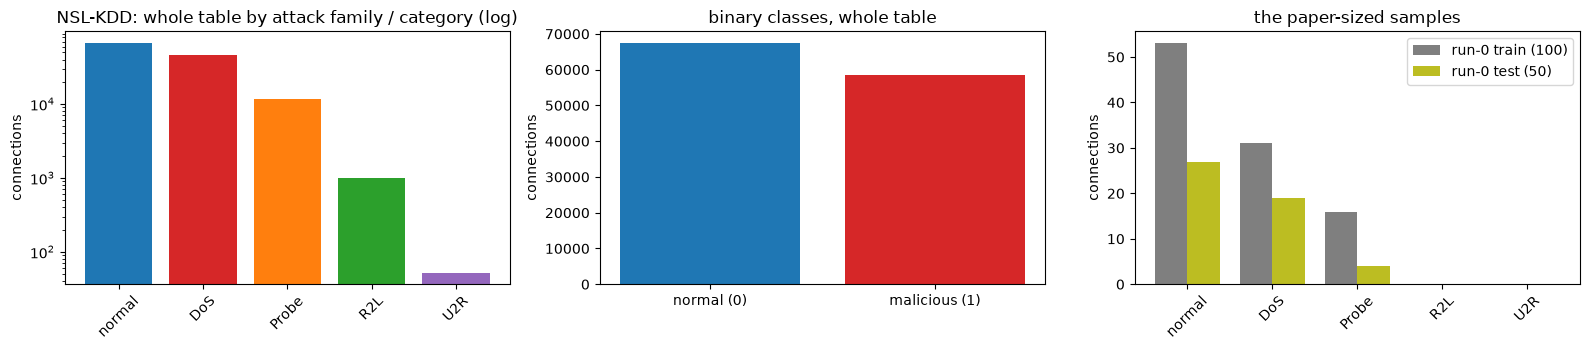

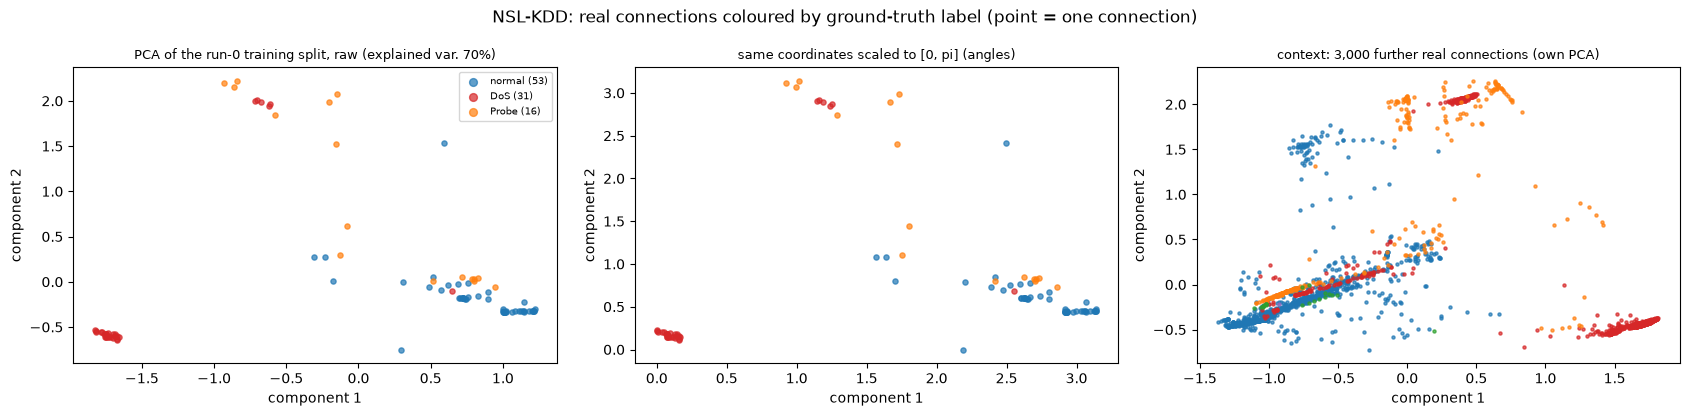

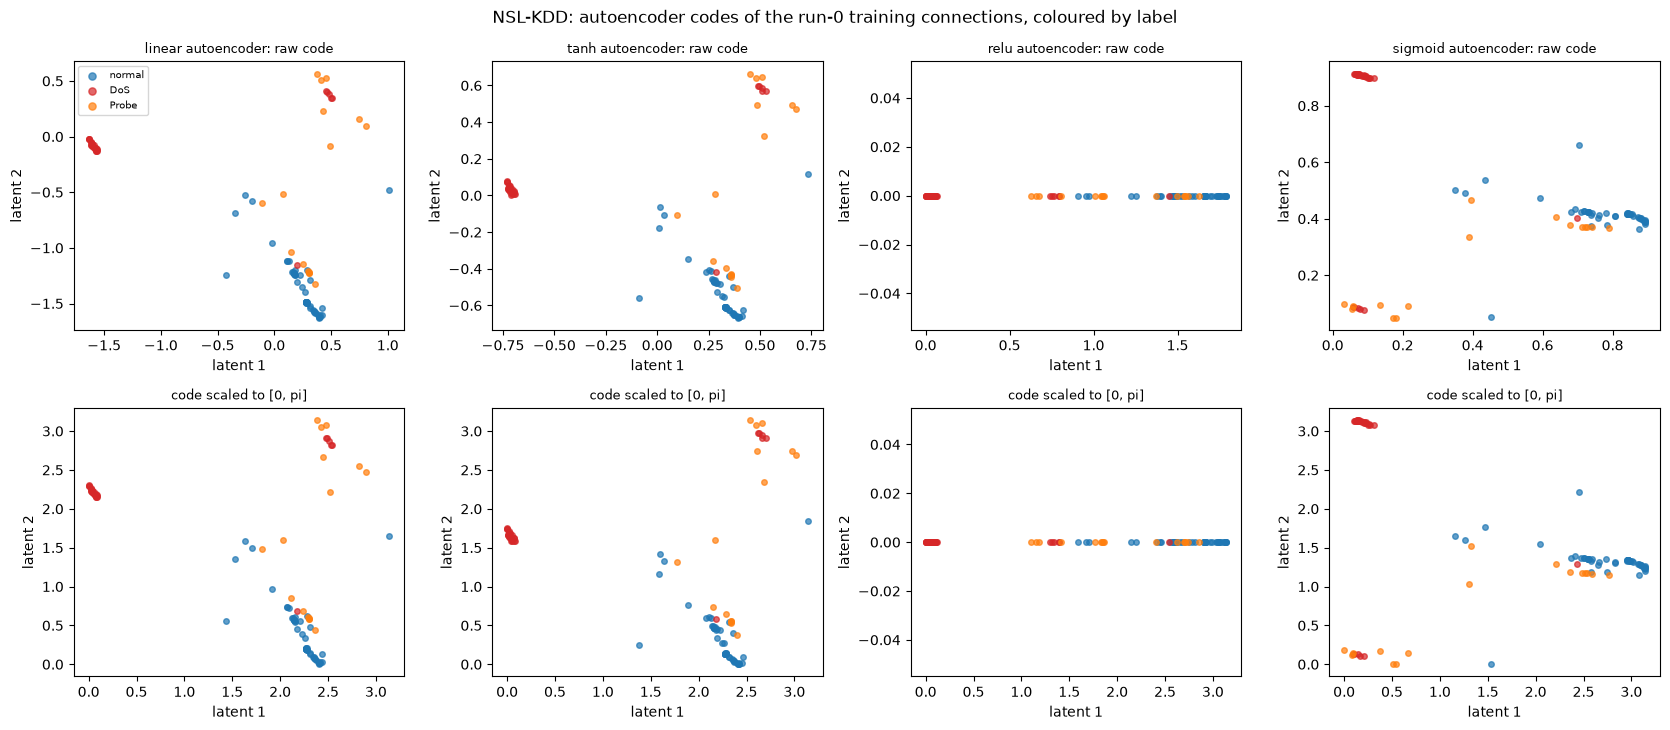

UNSW-NB15: raw table (175341, 44) -> numeric feature matrix (175341, 42) (official training partition (175,341 flows))
feature names (42): dur, proto, service, state, spkts, dpkts, sbytes, dbytes, rate, sttl, dttl, sload, dload, sloss, dloss, sintpkt, dintpkt, sjit, djit, swin, stcpb, dtcpb, dwin, tcprtt, synack, ackdat, smeansz, dmeansz, trans_depth, res_bdy_len, ct_srv_src, ct_state_ttl, ct_dst_ltm, ct_src_dport_ltm, ct_dst_sport_ltm, ct_dst_src_ltm, is_ftp_login, ct_ftp_cmd, ct_flw_http_mthd, ct_src_ltm, ct_srv_dst, is_sm_ips_ports
non-constant features kept for the autoencoder (42); constant on the pool: []


original label values and counts (whole table): {'Normal': 56000, 'Generic': 40000, 'Exploits': 33393, 'Fuzzers': 18184, 'DoS': 12264, 'Reconnaissance': 10491, 'Analysis': 2000, 'Backdoor': 1746, 'Shellcode': 1133, 'Worms': 130}
binary classes (0 = normal, 1 = malicious): {0: 56000, 1: 119341}
  run 0: training 150 -> {'Normal': 40, 'Generic': 36, 'Exploits': 27, 'Fuzzers': 19, 'DoS': 14, 'Reconnaissance': 10, 'Shellcode': 3, 'Analysis': 1} | test 50 -> {'Normal': 14, 'Generic': 9, 'Exploits': 9, 'Fuzzers': 8, 'DoS': 5, 'Shellcode': 2, 'Reconnaissance': 2, 'Backdoor': 1}
  run 1: training 150 -> {'Normal': 40, 'Exploits': 39, 'Generic': 31, 'Fuzzers': 17, 'Reconnaissance': 8, 'DoS': 8, 'Backdoor': 3, 'Analysis': 3, 'Worms': 1} | test 50 -> {'Normal': 14, 'Exploits': 11, 'Generic': 10, 'Fuzzers': 7, 'DoS': 2, 'Reconnaissance': 2, 'Analysis': 2, 'Backdoor': 1, 'Shellcode': 1}
  run 2: training 150 -> {'Normal': 41, 'Generic': 37, 'Exploits': 26, 'Fuzzers': 15, 'DoS': 14, 'Reconnaissance'

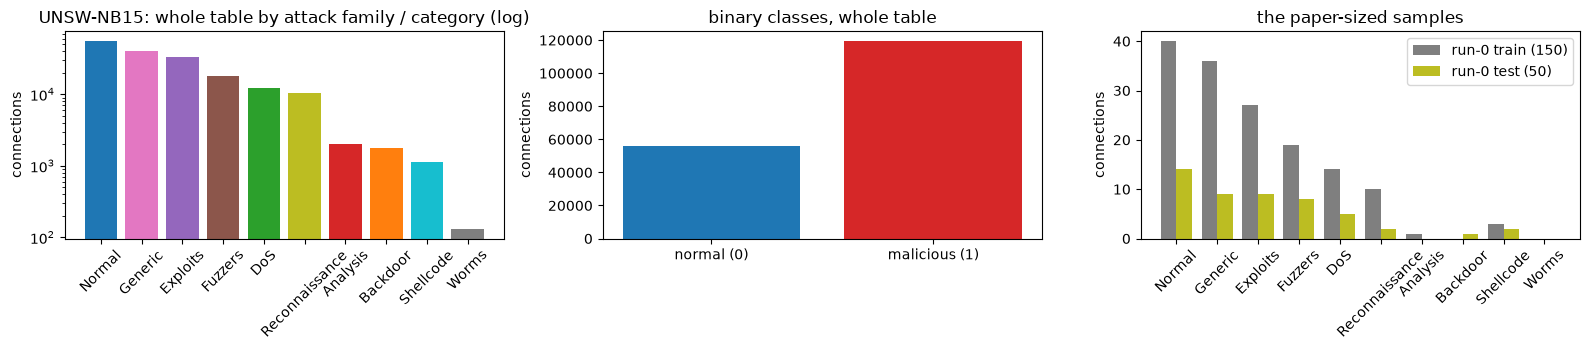

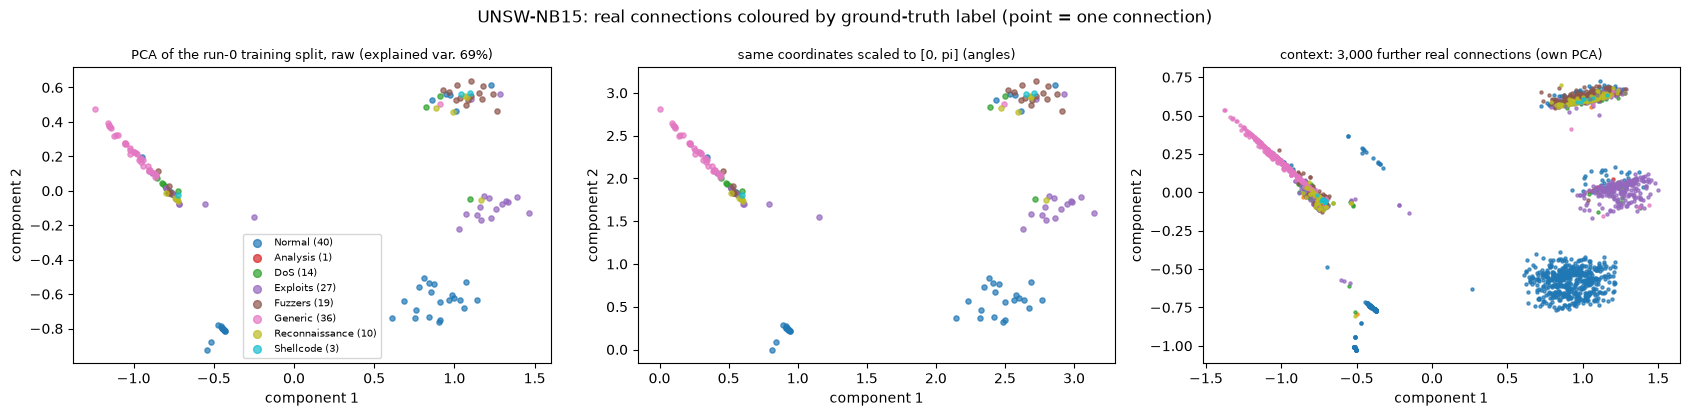

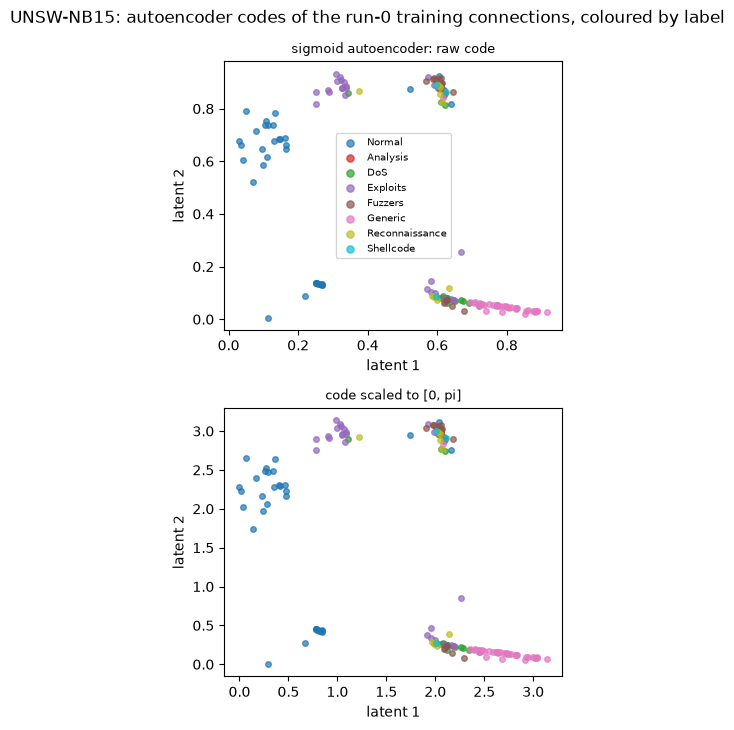

In [8]:
def palette(labels):
    others = ["tab:red", "tab:orange", "tab:green", "tab:purple", "tab:brown", "tab:pink", "tab:olive", "tab:cyan", "tab:gray", "gold", "black"]
    labels = sorted(set(labels), key=lambda s: (s not in ("normal", "Normal"), s)); col = {}; k = 0
    for l in labels:
        if l in ("normal", "Normal"):
            col[l] = "tab:blue"
        else:
            col[l] = others[k % len(others)]; k += 1
    return col

FAM_COL = {}
for name, d in DS.items():
    FAM_COL[name] = palette(d["family"])
    P = PART[name]; tr0, te0 = P["draws"][0]
    print("=" * 100)
    print(f"{name}: raw table {d['shape']} -> numeric feature matrix {d['X'].shape} ({d['source']})")
    print(f"feature names ({len(d['feats'])}): " + ", ".join(d["feats"]))
    print(f"non-constant features kept for the autoencoder ({len(P['cols'])}); constant on the pool: {sorted(set(d['feats']) - set(P['cols']))}")
    fine = pd.Series(d["fine"]).value_counts()
    print("original label values and counts (whole table):", fine.to_dict())
    if name == "NSL-KDD":
        print("attack families:", pd.Series(d["family"]).value_counts().to_dict())
    print("binary classes (0 = normal, 1 = malicious):", {int(k): int(v) for k, v in pd.Series(d["y"]).value_counts().sort_index().items()})
    for r in range(min(N_RUNS, 3)):
        tr, te = P["draws"][r]
        print(f"  run {r}: training {len(tr)} -> {pd.Series(d['family'][tr]).value_counts().to_dict()} | test {len(te)} -> {pd.Series(d['family'][te]).value_counts().to_dict()}")

    fig, axes = plt.subplots(1, 3, figsize=(16, 3.6))
    fam = pd.Series(d["family"]).value_counts()
    axes[0].bar(fam.index, fam.values, color=[FAM_COL[name][k] for k in fam.index]); axes[0].set_yscale("log"); axes[0].set_title(f"{name}: whole table by attack family / category (log)")
    axes[0].tick_params(axis="x", rotation=45)
    yb = pd.Series(d["y"]).value_counts().sort_index()
    axes[1].bar(["normal (0)", "malicious (1)"], yb.values, color=["tab:blue", "tab:red"]); axes[1].set_title("binary classes, whole table")
    w = 0.38; fm_tr = pd.Series(d["family"][tr0]).value_counts(); fm_te = pd.Series(d["family"][te0]).value_counts()
    idx = list(fam.index)
    axes[2].bar(np.arange(len(idx)) - w / 2, [fm_tr.get(k, 0) for k in idx], w, label=f"run-0 train ({len(tr0)})", color="tab:gray")
    axes[2].bar(np.arange(len(idx)) + w / 2, [fm_te.get(k, 0) for k in idx], w, label=f"run-0 test ({len(te0)})", color="tab:olive")
    axes[2].set_xticks(np.arange(len(idx))); axes[2].set_xticklabels(idx, rotation=45); axes[2].legend(); axes[2].set_title("the paper-sized samples")
    for a in axes: a.set_ylabel("connections")
    plt.tight_layout(); plt.show()

    # PCA of the normalised features: fitted on the run-0 training split; angles = min-max to [0, pi] fitted on the same split
    Xs = P["Xs"]
    pca = PCA(n_components=2, random_state=SEED).fit(Xs[tr0])
    Ptr, Pte = pca.transform(Xs[tr0]), pca.transform(Xs[te0])
    mm = MinMaxScaler((0.0, np.pi)).fit(Ptr); Atr = mm.transform(Ptr); Ate = np.clip(mm.transform(Pte), 0, np.pi)
    ctx = np.random.default_rng(SEED).choice(P["ae_pool"], min(3000, len(P["ae_pool"])), replace=False)
    pca_c = PCA(n_components=2, random_state=SEED).fit(Xs[ctx]); Pc = pca_c.transform(Xs[ctx])
    fig, axes = plt.subplots(1, 3, figsize=(17, 4.2))
    for ax, (Pts, fam_lab, title) in zip(axes, [(Ptr, d["family"][tr0], f"PCA of the run-0 training split, raw (explained var. {pca.explained_variance_ratio_.sum():.0%})"),
                                                 (Atr, d["family"][tr0], "same coordinates scaled to [0, pi] (angles)"),
                                                 (Pc, d["family"][ctx], "context: 3,000 further real connections (own PCA)")]):
        for l in FAM_COL[name]:
            m = fam_lab == l
            if m.any(): ax.scatter(Pts[m, 0], Pts[m, 1], s=14 if len(Pts) < 500 else 5, alpha=0.7, color=FAM_COL[name][l], label=f"{l} ({int(m.sum())})")
        ax.set_title(title, fontsize=9); ax.set_xlabel("component 1"); ax.set_ylabel("component 2")
    axes[0].legend(markerscale=1.5, fontsize=7)
    plt.suptitle(f"{name}: real connections coloured by ground-truth label (point = one connection)"); plt.tight_layout(); plt.show()

    # autoencoder codes (paper Figs. 3 to 7): raw 2-D code of the run-0 training split and the same codes scaled to [0, pi]
    acts = ACTIVATIONS[name]
    fig, axes = plt.subplots(2, len(acts), figsize=(4.2 * len(acts), 7.4), squeeze=False)
    for j, act in enumerate(acts):
        L = make_latent(name, act, N_QUBITS, tr0, te0)
        for l in FAM_COL[name]:
            m = d["family"][tr0] == l
            if m.any():
                axes[0, j].scatter(L["Z_train"][m, 0], L["Z_train"][m, 1], s=16, alpha=0.7, color=FAM_COL[name][l], label=l)
                axes[1, j].scatter(np.pi * L["A_train"][m, 0], np.pi * L["A_train"][m, 1], s=16, alpha=0.7, color=FAM_COL[name][l])
        axes[0, j].set_title(f"{ACT_NAME[act]} autoencoder: raw code", fontsize=9); axes[1, j].set_title("code scaled to [0, pi]", fontsize=9)
        axes[1, j].set_xlabel("latent 1"); axes[0, j].set_ylabel("latent 2"); axes[1, j].set_ylabel("latent 2"); axes[0, j].set_xlabel("latent 1")
    axes[0, 0].legend(markerscale=1.3, fontsize=7)
    plt.suptitle(f"{name}: autoencoder codes of the run-0 training connections, coloured by label"); plt.tight_layout(); plt.show()

## Quantum Circuit Architecture

The quantum part of the paper is a **kernel**, not a trained circuit: a connection $x$ (its 2-dimensional normalised
autoencoder code) is encoded into the state $|\Phi(x)\rangle = U_{\Phi(x)}H^{\otimes n}\cdots U_{\Phi(x)}H^{\otimes n}|0\rangle^{\otimes n}$
(Eq. 4, repeated `depth` times) and the kernel entry is $K(x,z)=|\langle\Phi(x)|\Phi(z)\rangle|^2$, the probability of reading all
zeros after $U(x)$ followed by $U(z)^\dagger$. The circuit that is executed is Qiskit's `zz_feature_map(n, reps=depth,
entanglement="full")`: per repetition a Hadamard on every qubit, a phase gate $P(2x_i)$ on every qubit, and for every
pair $(i,j)$ the block CX - $P\big(2(\pi-x_i)(\pi-x_j)\big)$ - CX. There are **no trainable circuit parameters**; the only
trained object is the classical SVM weight vector on the kernel. The cell below draws one circuit per distinct architecture
(each depth of Table I, each qubit count that is run), bound to the code of a real run-0 training connection, prints qubits,
depth, gate counts and parameter counts, and draws the compute-uncompute circuit that a quantum computer would run for one
kernel entry (with its measurement).

Assumptions where the paper omits circuit details: the paper gives the general form (Eq. 4 and Fig. 2) but not the data map
$\phi_S$, the number of qubits or the entanglement pattern; this notebook uses Qiskit's default ZZ data map (the one Aqua's
`SecondOrderExpansion` used), full entanglement and `reps = depth`. The paper's text in Section IV-C also describes amplitude
encoding, an SU(4) unitary and a $Z_1Z_2$ parity measurement, which belong to a variational classifier and are not part of the
QSVM experiment whose numbers are reported; they are not implemented.

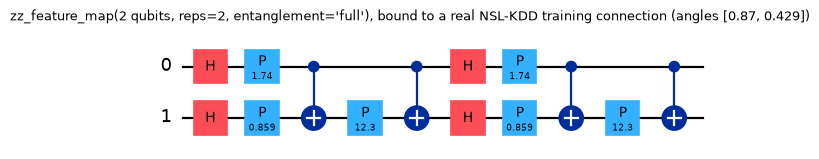

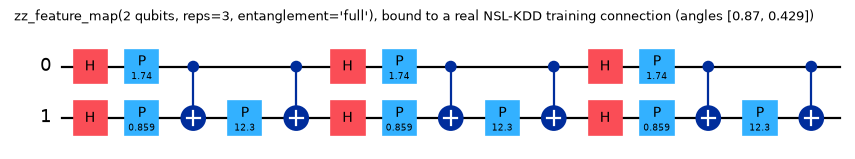

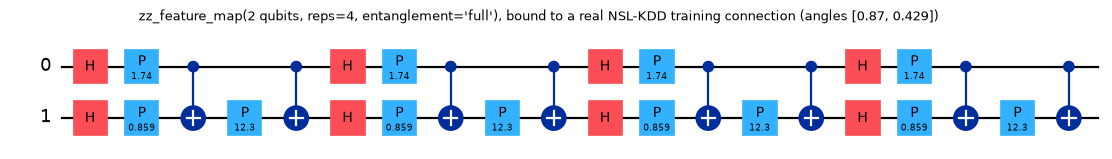

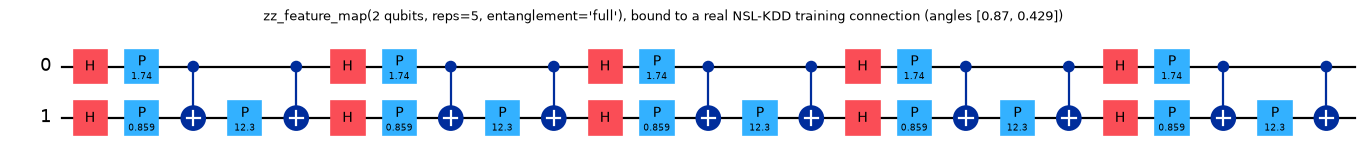

,qubits,depth_param,circuit_depth,input_parameters,trainable_parameters,gates
0,2,2,10,2,0,"{'p': 6, 'h': 4, 'cx': 4}"
1,2,3,15,2,0,"{'p': 9, 'h': 6, 'cx': 6}"
2,2,4,20,2,0,"{'p': 12, 'h': 8, 'cx': 8}"
3,2,5,25,2,0,"{'p': 15, 'h': 10, 'cx': 10}"


compute-uncompute kernel circuit (depth 3): 2 qubits | depth 31 | input parameters 4 | trainable parameters 0


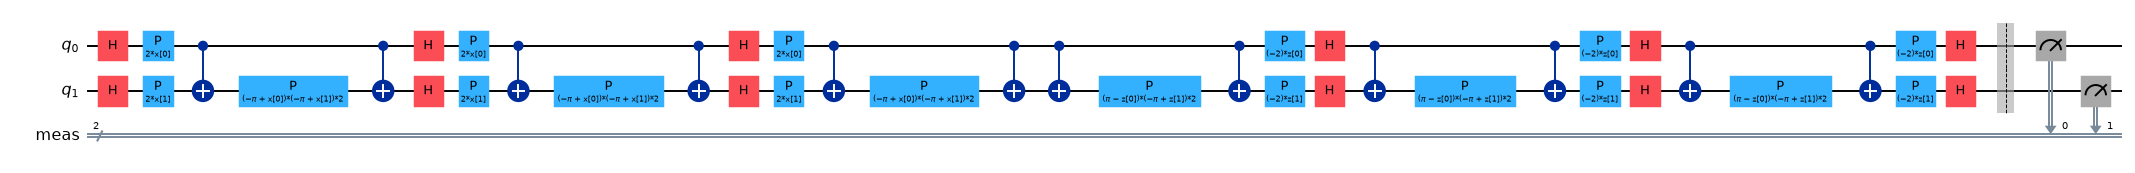

vectorised simulator == Qiskit Statevector of the drawn circuit for all 4 architectures (state overlap 1, max kernel difference 2.4e-15); 4 circuits drawn above


In [9]:
# --- a vectorised exact statevector simulator of exactly this circuit (used for the many repeated runs) ---
class ZZSim:
    """|phi(x)> = (D(x) H^n)^reps |0...0>, D(x) = diag(exp(i (sum_i 2 x_i b_i + sum_{i<j} 2 (pi-x_i)(pi-x_j) (b_i xor b_j))))
       = Qiskit's zz_feature_map(n, reps, entanglement). Qubit 0 is the least significant bit (Qiskit order)."""
    def __init__(self, n, reps, entanglement=ENTANGLEMENT):
        self.n, self.reps = n, reps
        self.pairs = [(i, j) for i in range(n) for j in range(i + 1, n)] if entanglement == "full" else [(i, i + 1) for i in range(n - 1)]
        b = np.arange(2 ** n); self.bits = np.stack([(b >> i) & 1 for i in range(n)], axis=1)       # (2^n, n)
        H = np.array([[1, 1], [1, -1]]) / np.sqrt(2); Hn = np.array([[1.0]])
        for _ in range(n): Hn = np.kron(Hn, H)
        self.Hn = Hn
    def states(self, A):
        A = np.atleast_2d(A); ph = 2 * A @ self.bits.T
        for i, j in self.pairs:
            ph = ph + (2 * (np.pi - A[:, [i]]) * (np.pi - A[:, [j]])) * (self.bits[:, i] ^ self.bits[:, j])[None, :]
        D = np.exp(1j * ph); psi = np.zeros((len(A), 2 ** self.n), complex); psi[:, 0] = 1
        for _ in range(self.reps):
            psi = D * (psi @ self.Hn.T)
        return psi

def fidelity(SA, SB):
    return np.abs(SA.conj() @ SB.T) ** 2

DIMS = [N_QUBITS] + EXTRA_DIMS
name0 = DATASETS[0]; tr0_, te0_ = PART[name0]["draws"][0]
rows = []; n_fig = 0
for dim in DIMS:
    if dim == N_QUBITS:
        x_demo = make_latent(name0, ACTIVATIONS[name0][-1], dim, tr0_, te0_)["A_train"][0]          # autoencoder code of a real connection
    else:
        Xs0 = PART[name0]["Xs"]; Pq = PCA(n_components=dim, random_state=SEED).fit(Xs0[tr0_]).transform(Xs0[tr0_])
        x_demo = MinMaxScaler().fit_transform(Pq)[0]                                                  # PCA code of a real connection (shape demo only)
    for depth in DEPTHS:
        fm = zz_feature_map(dim, reps=depth, entanglement=ENTANGLEMENT)
        bound = fm.assign_parameters(x_demo)
        rows.append(dict(qubits=dim, depth_param=depth, circuit_depth=fm.depth(), input_parameters=fm.num_parameters, trainable_parameters=0,
                         gates=dict(fm.count_ops())))
        fig = bound.draw("mpl", fold=40, scale=0.8); fig.suptitle(f"zz_feature_map({dim} qubits, reps={depth}, entanglement='{ENTANGLEMENT}'), bound to a real NSL-KDD training connection (angles {np.round(x_demo, 3).tolist()})", fontsize=9)
        display(fig); n_fig += 1
display(pd.DataFrame(rows))

# the circuit a quantum computer would run for one kernel entry (compute-uncompute), 2 qubits, depth 3, with measurement
xs, zs = ParameterVector("x", N_QUBITS), ParameterVector("z", N_QUBITS)
fm3 = zz_feature_map(N_QUBITS, reps=3, entanglement=ENTANGLEMENT)
kernel_circuit = QuantumCircuit(N_QUBITS)
kernel_circuit.compose(fm3.assign_parameters(list(xs)), inplace=True)
kernel_circuit.compose(fm3.assign_parameters(list(zs)).inverse(), inplace=True)
kernel_circuit.measure_all()
print("compute-uncompute kernel circuit (depth 3):", kernel_circuit.num_qubits, "qubits | depth", kernel_circuit.depth(), "| input parameters", kernel_circuit.num_parameters, "| trainable parameters 0")
fig = kernel_circuit.draw("mpl", fold=45, scale=0.7); display(fig)

# equivalence: the vectorised simulator equals Qiskit's Statevector of the drawn circuit for every (qubits, depth) used
rs = np.random.default_rng(0); worst = 0.0
for dim in DIMS:
    for depth in DEPTHS:
        fmq = zz_feature_map(dim, reps=depth, entanglement=ENTANGLEMENT)
        pts = rs.uniform(0, math.pi, (25, dim)); S_vec = ZZSim(dim, depth).states(pts)
        S_q = np.array([Statevector(fmq.assign_parameters(a)).data for a in pts])
        ov = np.abs(np.einsum("ij,ij->i", S_vec.conj(), S_q))
        assert np.allclose(ov, 1.0, atol=1e-9), f"simulator differs from Qiskit for {dim} qubits, depth {depth}"
        assert np.allclose(fidelity(S_vec, S_vec), fidelity(S_q, S_q), atol=1e-9)
        worst = max(worst, float(np.abs(fidelity(S_vec, S_vec) - fidelity(S_q, S_q)).max()))
print(f"vectorised simulator == Qiskit Statevector of the drawn circuit for all {len(DIMS) * len(DEPTHS)} architectures (state overlap 1, max kernel difference {worst:.1e}); {n_fig} circuits drawn above")

## 4. The quantum kernel and the QSVM

The paper's protocol (Havlicek "method 2") is: estimate $K(x_i,x_j)$ for all pairs of training points, solve the SVM dual
(Eq. 5) on a classical computer, then estimate $K(s,x_i)$ of each test point against the training points and classify with
Eq. 6. With a statevector simulator the two kernel estimations are exact matrix products of statevectors, and the dual is solved
by `SVC(kernel="precomputed", C)`, which is what Qiskit's `QSVC` does as well. Section 7 asserts the kernels and the predictions
agree with Qiskit's own `FidelityStatevectorKernel` + `QSVC`.

Two versions of every QSVM are trained for every depth:

* **as published**: the normalised code goes in as angles (bandwidth 1) and `C = 1`, i.e. the Aqua defaults;
* **tuned**: the angle bandwidth (a factor on all angles; the value $\pi$ means the code is scaled to $[0,\pi]$) and `C` are chosen
  by accuracy on an inner stratified 75 : 25 split of the *training* sample; the test sample is never touched. Ties go to the
  first grid entry, i.e. the paper's setting.

Wall-clock time covers the two kernel evaluations, the SVM fit and the prediction.

In [10]:
def metrics(y, p):
    tn, fp, fn, tp = confusion_matrix(y, p, labels=[0, 1]).ravel()          # attack = positive class
    return dict(accuracy=accuracy_score(y, p), precision=precision_score(y, p, zero_division=0), recall=recall_score(y, p, zero_division=0),
                f1=f1_score(y, p, zero_division=0), fpr=fp / max(fp + tn, 1), fnr=fn / max(fn + tp, 1))

def inner_split(y, seed):
    return train_test_split(np.arange(len(y)), test_size=VAL_FRACTION, stratify=y, random_state=seed)

def tune_qsvm(sim, A, y, seed):
    """CHOICE: best (bandwidth, C) by accuracy on the inner validation split of the training rows; ties -> first in grid order."""
    itr, iva = inner_split(y, seed); best = None
    for bw in BW_GRID:
        S = sim.states(bw * A); K = fidelity(S, S)
        for C in C_GRID:
            m = SVC(kernel="precomputed", C=C).fit(K[np.ix_(itr, itr)], y[itr])
            acc = float((m.predict(K[np.ix_(iva, itr)]) == y[iva]).mean())
            if best is None or acc > best[0]:
                best = (acc, bw, C)
    return best

def qsvm_fit_predict(sim, A_tr, y_tr, A_te, bw, C):
    t0 = time.perf_counter()
    S_tr, S_te = sim.states(bw * A_tr), sim.states(bw * A_te)
    K_tr, K_te = fidelity(S_tr, S_tr), fidelity(S_te, S_tr)
    p = SVC(kernel="precomputed", C=C).fit(K_tr, y_tr).predict(K_te)
    return p, seconds_since(t0), K_tr, K_te

def tuned_rbf(X, y, seed, gammas):
    itr, iva = inner_split(y, seed); best = None
    for C in SVM_C_GRID:
        for g in gammas:
            acc = SVC(kernel="rbf", C=C, gamma=g).fit(X[itr], y[itr]).score(X[iva], y[iva])
            if best is None or acc > best[0]:
                best = (acc, C, g)
    return SVC(kernel="rbf", C=best[1], gamma=best[2]), best

ROWS, PRED0, LAT0 = [], {}, {}
def run_cell(name, act, dim, mode):
    d = DS[name]; y = d["y"]; Xs = PART[name]["Xs"]
    for r, (tr, te) in enumerate(PART[name]["draws"]):
        seed = SEED + r; ytr, yte = y[tr], y[te]
        L = make_latent(name, act, dim, tr, te, mode, seed); Atr, Ate = L["A_train"], L["A_test"]
        if r == 0: LAT0[(name, act, dim, mode)] = L
        base = dict(dataset=name, activation=act, dim=dim, mode=mode, run=r)
        def add(model, depth, variant, p, dt, **kw):
            ROWS.append(dict(base, model=model, depth=depth, variant=variant, time_s=dt, **metrics(yte, p), **kw))
            if r == 0: PRED0[(name, act, dim, mode, model, depth, variant)] = p
        # --- classical references on exactly the same inputs ---
        add("majority class", np.nan, "-", np.full(len(yte), np.bincount(ytr).argmax()), 0.0)
        t0 = time.perf_counter(); p = SVC(kernel="rbf").fit(Atr, ytr).predict(Ate); add("RBF-SVM default", np.nan, "-", p, seconds_since(t0))
        t0 = time.perf_counter(); m, b = tuned_rbf(Atr, ytr, seed, SVM_G_GRID); p = m.fit(Atr, ytr).predict(Ate); add("RBF-SVM tuned", np.nan, "-", p, seconds_since(t0), val_acc=b[0])
        t0 = time.perf_counter(); p = RandomForestClassifier(n_estimators=200, random_state=seed).fit(Atr, ytr).predict(Ate); add("RandomForest", np.nan, "-", p, seconds_since(t0))
        if mode == "pool":                                     # the same 100 / 150 connections with all normalised features (no autoencoder)
            t0 = time.perf_counter(); m, b = tuned_rbf(Xs[tr], ytr, seed, ALLFEAT_G_GRID); p = m.fit(Xs[tr], ytr).predict(Xs[te]); add("RBF-SVM tuned, all features", np.nan, "-", p, seconds_since(t0), val_acc=b[0])
            t0 = time.perf_counter(); p = RandomForestClassifier(n_estimators=200, random_state=seed).fit(Xs[tr], ytr).predict(Xs[te]); add("RandomForest, all features", np.nan, "-", p, seconds_since(t0))
        # --- the quantum-kernel SVM at every depth ---
        for depth in DEPTHS:
            sim = ZZSim(dim, depth)
            p, dt, _, _ = qsvm_fit_predict(sim, Atr, ytr, Ate, 1.0, 1.0); add("QSVM", depth, "as published", p, dt, bw=1.0, C=1.0)
            va, bw, C = tune_qsvm(sim, Atr, ytr, seed)
            p, dt, _, _ = qsvm_fit_predict(sim, Atr, ytr, Ate, bw, C); add("QSVM", depth, "tuned", p, dt, bw=bw, C=C, val_acc=va)

## 5. Running the experiment

For every dataset and every autoencoder activation of the paper, and for every random draw of the paper-sized sample, the
cell below trains the QSVM at depths 2 to 5 (as published and tuned) and the classical references on the identical latent
codes: majority class, RBF-SVM with scikit-learn defaults, RBF-SVM tuned on the same inner validation split, and a random
forest. Two extra references use the same 100 (150) connections with **all** normalised features and no autoencoder.

The paper does not say which activation its Table I belongs to. The headline activation per dataset is chosen **without
looking at test data**: it is the one with the highest mean inner-validation accuracy of the tuned QSVM over runs and depths.
All activations are reported anyway.

In [11]:
t0 = time.perf_counter()
for name in DATASETS:
    for act in ACTIVATIONS[name]:
        run_cell(name, act, N_QUBITS, "pool")
        print(f"{name} / {ACT_NAME[act]}: {N_RUNS} runs done ({seconds_since(t0):.0f} s elapsed)")
RES = pd.DataFrame(ROWS)
sel = RES[(RES.model == "QSVM") & (RES.variant == "tuned") & (RES.dim == N_QUBITS) & (RES["mode"] == "pool")].groupby(["dataset", "activation"]).val_acc.mean()
HEAD = {name: sel[name].idxmax() for name in DATASETS}
print("inner-validation accuracy of the tuned QSVM (mean over runs and depths):")
display(sel.unstack().rename(columns=ACT_NAME).round(3))
print("headline activation (chosen on training data only):", {k: ACT_NAME[v] for k, v in HEAD.items()})
for dim in EXTRA_DIMS:
    for name in DATASETS:
        run_cell(name, HEAD[name], dim, "pool")
    print(f"extra latent size {dim} qubits done ({seconds_since(t0):.0f} s elapsed)")
RES = pd.DataFrame(ROWS)
print(f"{len(RES)} result rows in {seconds_since(t0):.0f} s")

NSL-KDD / linear: 3 runs done (19 s elapsed)


NSL-KDD / tanh: 3 runs done (57 s elapsed)


NSL-KDD / relu: 3 runs done (126 s elapsed)


NSL-KDD / sigmoid: 3 runs done (158 s elapsed)


UNSW-NB15 / sigmoid: 3 runs done (203 s elapsed)


inner-validation accuracy of the tuned QSVM (mean over runs and depths):


activation,linear,sigmoid,relu,tanh
dataset,,,,
NSL-KDD,0.967,0.947,0.91,0.967
UNSW-NB15,NaN,0.956,NaN,NaN


headline activation (chosen on training data only): {'NSL-KDD': 'linear', 'UNSW-NB15': 'sigmoid'}
210 result rows in 204 s


## 6. Results: metrics, the accuracy-versus-depth plot, kernel matrices and confusion matrices

First the numbers: accuracy (mean +- std over the `N_RUNS` draws, and the single run-0 draw), precision, recall and F1 with the
attack as the positive class, and the time per model, for the headline activation of each dataset (all activations follow). Then
the paper's Fig. 8 (accuracy against circuit depth), the training kernel matrices of Figs. 9 and 10 (training connections
sorted by class: first the normal ones, then the malicious ones; a clear dark/bright block structure means the kernel
separates the classes), and the confusion matrices of run 0.

In [12]:
def pick(df, **kw):
    for k, v in kw.items():
        if isinstance(v, float) and np.isnan(v):
            df = df[df[k].isna()]
        else:
            df = df[df[k] == v]
    return df

def ms(x):
    return f"{x.mean():.3f} +- {(x.std(ddof=1) if len(x) > 1 else 0.0):.3f}"

def headline_table(name, act, dim=N_QUBITS, mode="pool"):
    d = RES[(RES.dataset == name) & (RES.activation == act) & (RES.dim == dim) & (RES["mode"] == mode)]
    first = d[d.run == 0][["model", "depth", "variant"]]
    out = []
    for _, r in first.iterrows():
        g = pick(d, model=r.model, depth=r.depth, variant=r.variant)
        out.append(dict(model=r.model, depth="" if np.isnan(r.depth) else int(r.depth), variant=r.variant, accuracy_mean_std=ms(g.accuracy),
                        accuracy_run0=round(float(g[g.run == 0].accuracy.iloc[0]), 3), precision=round(g.precision.mean(), 3), recall=round(g.recall.mean(), 3),
                        f1=round(g.f1.mean(), 3), time_s=round(g.time_s.mean(), 3)))
    return pd.DataFrame(out)

for name in DATASETS:
    print(f"===== {name}, {ACT_NAME[HEAD[name]]} autoencoder, {N_QUBITS} qubits, {N_RUNS} draws of {N_TRAIN[name]} / {N_TEST[name]} connections (attack = positive class) =====")
    display(headline_table(name, HEAD[name]))

print("===== all autoencoder activations: QSVM test accuracy, mean over draws =====")
act_rows = []
for name in DATASETS:
    for act in ACTIVATIONS[name]:
        d = RES[(RES.dataset == name) & (RES.activation == act) & (RES.dim == N_QUBITS) & (RES["mode"] == "pool")]
        row = dict(dataset=name, activation=ACT_NAME[act])
        for variant in ("as published", "tuned"):
            for depth in DEPTHS:
                row[f"{variant[:5]} d{depth}"] = round(pick(d, model="QSVM", depth=float(depth), variant=variant).accuracy.mean(), 3)
        row["RBF-SVM tuned"] = round(pick(d, model="RBF-SVM tuned").accuracy.mean(), 3)
        row["RandomForest"] = round(pick(d, model="RandomForest").accuracy.mean(), 3)
        act_rows.append(row)
display(pd.DataFrame(act_rows))

if EXTRA_DIMS:
    print("===== latent size (= number of qubits) for the headline activation: accuracy mean +- std over draws =====")
    dim_rows = []
    for name in DATASETS:
        for dim in DIMS:
            d = RES[(RES.dataset == name) & (RES.activation == HEAD[name]) & (RES.dim == dim) & (RES["mode"] == "pool")]
            row = dict(dataset=name, qubits=dim)
            for dp in DEPTHS:
                row[f"QSVM as published d{dp}"] = ms(pick(d, model="QSVM", depth=float(dp), variant="as published").accuracy)
            row["QSVM tuned d3"] = ms(pick(d, model="QSVM", depth=3.0, variant="tuned").accuracy)
            row["RBF-SVM tuned"] = ms(pick(d, model="RBF-SVM tuned").accuracy); row["RandomForest"] = ms(pick(d, model="RandomForest").accuracy)
            dim_rows.append(row)
    display(pd.DataFrame(dim_rows))

===== NSL-KDD, linear autoencoder, 2 qubits, 3 draws of 100 / 50 connections (attack = positive class) =====


,model,depth,variant,accuracy_mean_std,accuracy_run0,precision,recall,f1,time_s
0,majority class,,-,0.533 +- 0.012,0.54,0.000,0.000,0.000,0.000
1,RBF-SVM default,,-,0.853 +- 0.042,0.84,0.944,0.728,0.821,0.072
2,RBF-SVM tuned,,-,0.847 +- 0.012,0.84,0.921,0.742,0.817,0.405
3,RandomForest,,-,0.847 +- 0.050,0.90,0.891,0.771,0.826,1.866
4,"RBF-SVM tuned, all features",,-,0.933 +- 0.031,0.94,0.954,0.901,0.926,0.693
5,"RandomForest, all features",,-,0.920 +- 0.053,0.94,0.927,0.901,0.914,2.121
6,QSVM,2,as published,0.840 +- 0.060,0.84,0.878,0.771,0.816,0.005
7,QSVM,2,tuned,0.853 +- 0.046,0.88,0.857,0.828,0.835,0.008
8,QSVM,3,as published,0.800 +- 0.040,0.84,0.846,0.717,0.763,0.005
9,QSVM,3,tuned,0.860 +- 0.072,0.94,0.851,0.856,0.845,0.006


===== UNSW-NB15, sigmoid autoencoder, 2 qubits, 3 draws of 150 / 50 connections (attack = positive class) =====


,model,depth,variant,accuracy_mean_std,accuracy_run0,precision,recall,f1,time_s
0,majority class,,-,0.720 +- 0.000,0.72,0.720,1.000,0.837,0.000
1,RBF-SVM default,,-,0.927 +- 0.023,0.94,0.908,1.000,0.952,0.050
2,RBF-SVM tuned,,-,0.927 +- 0.023,0.94,0.908,1.000,0.952,0.794
3,RandomForest,,-,0.920 +- 0.020,0.92,0.900,1.000,0.947,3.636
4,"RBF-SVM tuned, all features",,-,0.927 +- 0.023,0.94,0.908,1.000,0.952,0.278
5,"RandomForest, all features",,-,0.913 +- 0.012,0.92,0.915,0.972,0.942,3.422
6,QSVM,2,as published,0.927 +- 0.023,0.94,0.908,1.000,0.952,0.058
7,QSVM,2,tuned,0.927 +- 0.023,0.94,0.908,1.000,0.952,0.070
8,QSVM,3,as published,0.907 +- 0.012,0.92,0.885,1.000,0.939,0.055
9,QSVM,3,tuned,0.913 +- 0.012,0.92,0.893,1.000,0.943,0.074


===== all autoencoder activations: QSVM test accuracy, mean over draws =====


,dataset,activation,as pu d2,as pu d3,as pu d4,as pu d5,tuned d2,tuned d3,tuned d4,tuned d5,RBF-SVM tuned,RandomForest
0,NSL-KDD,linear,0.840,0.800,0.853,0.860,0.853,0.860,0.853,0.873,0.847,0.847
1,NSL-KDD,tanh,0.833,0.800,0.833,0.860,0.847,0.847,0.860,0.860,0.847,0.853
2,NSL-KDD,relu,0.860,0.853,0.853,0.853,0.860,0.853,0.867,0.860,0.860,0.860
3,NSL-KDD,sigmoid,0.847,0.840,0.833,0.840,0.847,0.860,0.847,0.860,0.847,0.867
4,UNSW-NB15,sigmoid,0.927,0.907,0.887,0.893,0.927,0.913,0.913,0.900,0.927,0.920


classical RBF-SVM on the large pools (275 s):


,dataset,activation,n_train,n_test,params,time_s,accuracy,precision,recall,f1,fpr,fnr
0,NSL-KDD,linear,4000,4000,"{'C': 100.0, 'gamma': 64.0}",4.8723,0.9340,0.9545,0.9028,0.9279,0.0382,0.0972
1,NSL-KDD,tanh,4000,4000,"{'C': 100.0, 'gamma': 64.0}",10.0535,0.9340,0.9535,0.9038,0.9280,0.0392,0.0962
2,NSL-KDD,relu,4000,4000,"{'C': 100.0, 'gamma': 64.0}",72.8453,0.8942,0.9484,0.8199,0.8795,0.0397,0.1801
3,NSL-KDD,sigmoid,4000,4000,"{'C': 10.0, 'gamma': 64.0}",7.6516,0.9390,0.9596,0.9086,0.9334,0.0340,0.0914
4,UNSW-NB15,sigmoid,4000,4000,"{'C': 1.0, 'gamma': 64.0}",17.9546,0.9260,0.9069,0.9942,0.9485,0.2228,0.0058


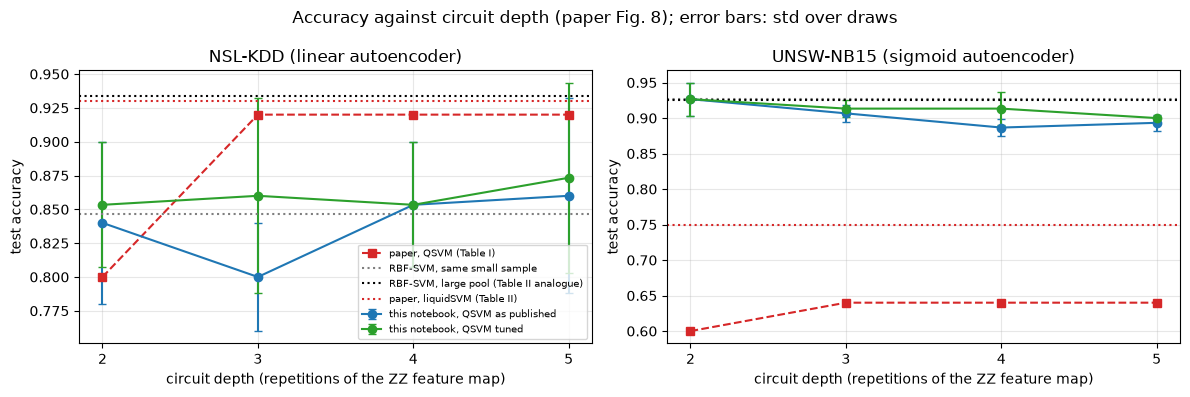

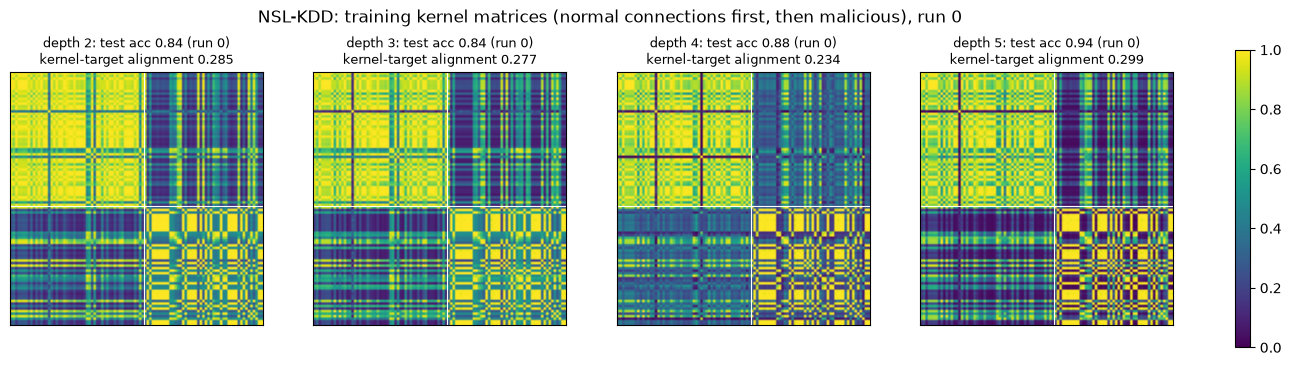

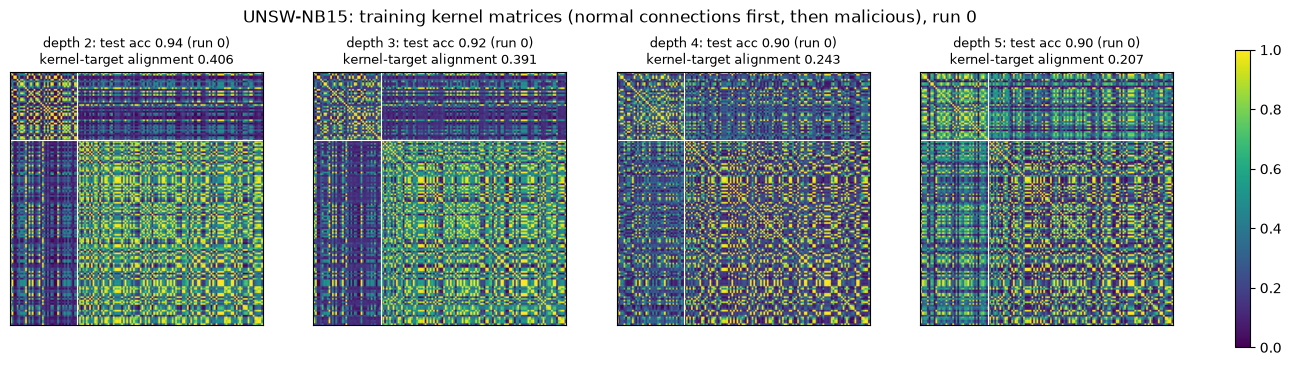

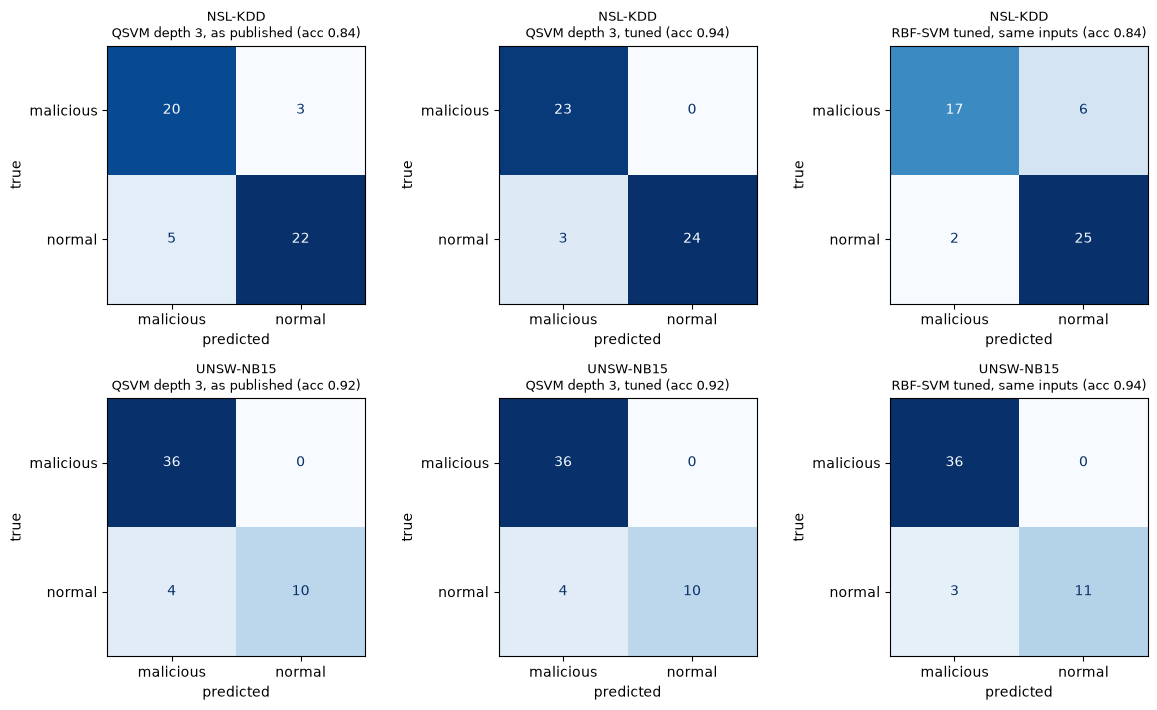

In [13]:
# paper Fig. 8: accuracy against circuit depth
PAPER_T1 = {"NSL-KDD": {2: 0.80, 3: 0.92, 4: 0.92, 5: 0.92}, "UNSW-NB15": {2: 0.60, 3: 0.64, 4: 0.64, 5: 0.64}}
PAPER_T2 = {"NSL-KDD": (0.93, 0.136, 0.019), "UNSW-NB15": (0.75, 0.132, 0.383)}      # accuracy, positive / negative validation error

BIG = {}
def big_svm(name, act):
    P, d = PART[name], DS[name]; ae = get_ae(name, act, N_QUBITS); Xs = P["Xs"]
    Ztr = ae.encode(Xs[P["big_train"]]); mm = MinMaxScaler().fit(Ztr)
    Atr, Ate = mm.transform(Ztr), np.clip(mm.transform(ae.encode(Xs[P["big_test"]])), 0, 1)
    ytr, yte = d["y"][P["big_train"]], d["y"][P["big_test"]]
    sub = np.random.default_rng(SEED).choice(len(Atr), min(2000, len(Atr)), replace=False)
    gs = GridSearchCV(SVC(kernel="rbf"), {"C": SVM_C_GRID, "gamma": SVM_G_GRID}, cv=3, n_jobs=1).fit(Atr[sub], ytr[sub])   # liquidSVM-style automatic k-fold selection
    t0 = time.perf_counter(); p = SVC(kernel="rbf", **gs.best_params_).fit(Atr, ytr).predict(Ate); dt = seconds_since(t0)
    return dict(n_train=len(Atr), n_test=len(Ate), params=gs.best_params_, time_s=dt, **metrics(yte, p))

t0 = time.perf_counter()
for name in DATASETS:
    for act in ACTIVATIONS[name]:
        BIG[(name, act)] = big_svm(name, act)
print(f"classical RBF-SVM on the large pools ({seconds_since(t0):.0f} s):")
display(pd.DataFrame([dict(dataset=k[0], activation=ACT_NAME[k[1]], **{kk: (round(v, 4) if isinstance(v, float) else v) for kk, v in r.items()}) for k, r in BIG.items()]))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, name in zip(axes, DATASETS):
    act = HEAD[name]
    for variant, c in (("as published", "tab:blue"), ("tuned", "tab:green")):
        g = [pick(RES[(RES.dataset == name) & (RES.activation == act) & (RES.dim == N_QUBITS) & (RES["mode"] == "pool")], model="QSVM", depth=float(dp), variant=variant).accuracy for dp in DEPTHS]
        ax.errorbar(DEPTHS, [x.mean() for x in g], yerr=[x.std(ddof=1) if len(x) > 1 else 0 for x in g], marker="o", color=c, capsize=3, label=f"this notebook, QSVM {variant}")
    ax.plot(DEPTHS, [PAPER_T1[name][dp] for dp in DEPTHS], "s--", color="tab:red", label="paper, QSVM (Table I)")
    rbf = pick(RES[(RES.dataset == name) & (RES.activation == act) & (RES.dim == N_QUBITS) & (RES["mode"] == "pool")], model="RBF-SVM tuned").accuracy.mean()
    ax.axhline(rbf, color="tab:gray", ls=":", label="RBF-SVM, same small sample")
    ax.axhline(BIG[(name, act)]["accuracy"], color="k", ls=":", label="RBF-SVM, large pool (Table II analogue)")
    ax.axhline(PAPER_T2[name][0], color="tab:red", ls=":", label="paper, liquidSVM (Table II)")
    ax.set_xticks(DEPTHS); ax.set_xlabel("circuit depth (repetitions of the ZZ feature map)"); ax.set_ylabel("test accuracy")
    ax.set_title(f"{name} ({ACT_NAME[act]} autoencoder)"); ax.grid(alpha=0.3)
axes[0].legend(fontsize=7, loc="lower right")
plt.suptitle("Accuracy against circuit depth (paper Fig. 8); error bars: std over draws"); plt.tight_layout(); plt.show()

# paper Figs. 9 and 10: training kernel matrices (bandwidth 1 = as published), sorted by class
KTA = {}
for name in DATASETS:
    act = HEAD[name]; d = DS[name]
    fig, axes = plt.subplots(1, len(DEPTHS), figsize=(4 * len(DEPTHS), 3.9))
    for ax, depth in zip(axes, DEPTHS):
        ktas = []
        for r, (tr, te) in enumerate(PART[name]["draws"]):
            Atr = make_latent(name, act, N_QUBITS, tr, te)["A_train"] if r else LAT0[(name, act, N_QUBITS, "pool")]["A_train"]
            S = ZZSim(N_QUBITS, depth).states(Atr); K = fidelity(S, S); ypm = 2.0 * d["y"][tr] - 1.0
            ktas.append(float((K * np.outer(ypm, ypm)).sum() / (np.linalg.norm(K) * np.linalg.norm(np.outer(ypm, ypm)))))
            if r == 0:
                order = np.argsort(d["y"][tr], kind="stable"); n0 = int((d["y"][tr] == 0).sum())
                im = ax.imshow(K[np.ix_(order, order)], cmap="viridis", vmin=0, vmax=1); ax.axhline(n0 - 0.5, color="w", lw=0.8); ax.axvline(n0 - 0.5, color="w", lw=0.8)
                acc0 = float(RES[(RES.dataset == name) & (RES.activation == act) & (RES.dim == N_QUBITS) & (RES["mode"] == "pool") & (RES.run == 0) & (RES.model == "QSVM") & (RES.depth == depth) & (RES.variant == "as published")].accuracy.iloc[0])
        KTA[(name, depth)] = float(np.mean(ktas))
        ax.set_title(f"depth {depth}: test acc {acc0:.2f} (run 0)\nkernel-target alignment {np.mean(ktas):.3f}", fontsize=9); ax.set_xticks([]); ax.set_yticks([])
    fig.colorbar(im, ax=axes, fraction=0.012); plt.suptitle(f"{name}: training kernel matrices (normal connections first, then malicious), run 0"); plt.show()

# confusion matrices of run 0 (attack = positive class)
fig, axes = plt.subplots(2, 3, figsize=(12, 7.2))
for row, name in enumerate(DATASETS):
    act = HEAD[name]; tr, te = PART[name]["draws"][0]; yte = DS[name]["y"][te]
    for ax, (title, key) in zip(axes[row], [("QSVM depth 3, as published", (name, act, N_QUBITS, "pool", "QSVM", 3, "as published")),
                                              ("QSVM depth 3, tuned", (name, act, N_QUBITS, "pool", "QSVM", 3, "tuned")),
                                              ("RBF-SVM tuned, same inputs", (name, act, N_QUBITS, "pool", "RBF-SVM tuned", np.nan, "-"))]):
        p = PRED0[key]
        ConfusionMatrixDisplay(confusion_matrix(yte, p, labels=[1, 0]), display_labels=["malicious", "normal"]).plot(ax=ax, colorbar=False, cmap="Blues")
        ax.set_title(f"{name}\n{title} (acc {accuracy_score(yte, p):.2f})", fontsize=9); ax.set_xlabel("predicted"); ax.set_ylabel("true")
plt.tight_layout(); plt.show()

## 7. Cross-check against Qiskit's own kernel and QSVC

All repeated runs above use the vectorised statevector simulator `ZZSim`. This section checks it against the Qiskit
objects the paper's `QSVM()` corresponds to: for run 0 and the headline activation of each dataset, the training and test kernel
matrices are computed by `FidelityStatevectorKernel(feature_map=zz_feature_map(...))` (which executes the drawn circuit for every
input), they must equal the simulator's matrices, and an SVM trained on Qiskit's matrices must make the same predictions.
At the deepest checked circuit the full `QSVC` class is trained and used for prediction as well.

In [14]:
t0 = time.perf_counter(); chk = []
for name in DATASETS:
    act = HEAD[name]; d = DS[name]; tr, te = PART[name]["draws"][0]; ytr, yte = d["y"][tr], d["y"][te]
    L = LAT0[(name, act, N_QUBITS, "pool")]; Atr, Ate = L["A_train"], L["A_test"]
    for depth in QISKIT_DEPTHS:
        for variant in ("as published", "tuned"):
            r0 = RES[(RES.dataset == name) & (RES.activation == act) & (RES.dim == N_QUBITS) & (RES["mode"] == "pool") & (RES.run == 0) & (RES.model == "QSVM") & (RES.depth == depth) & (RES.variant == variant)].iloc[0]
            bw, C = float(r0.bw), float(r0.C)
            qk = FidelityStatevectorKernel(feature_map=zz_feature_map(N_QUBITS, reps=depth, entanglement=ENTANGLEMENT))
            tq = time.perf_counter(); Kq_tr = qk.evaluate(bw * Atr); Kq_te = qk.evaluate(bw * Ate, bw * Atr); tq = seconds_since(tq)
            p_sim, t_sim, K_tr, K_te = qsvm_fit_predict(ZZSim(N_QUBITS, depth), Atr, ytr, Ate, bw, C)
            assert np.allclose(Kq_tr, K_tr, atol=1e-8) and np.allclose(Kq_te, K_te, atol=1e-8), "kernel differs from Qiskit"
            p_q = SVC(kernel="precomputed", C=C).fit(Kq_tr, ytr).predict(Kq_te)
            assert (p_q == p_sim).all() and (p_sim == PRED0[(name, act, N_QUBITS, "pool", "QSVM", depth, variant)]).all()
            used_qsvc = ""
            if depth == QISKIT_DEPTHS[-1]:
                p_qsvc = QSVC(quantum_kernel=qk, C=C).fit(bw * Atr, ytr).predict(bw * Ate)
                assert (p_qsvc == p_sim).all(); used_qsvc = "QSVC predictions identical"
            chk.append(dict(dataset=name, depth=depth, variant=variant, bandwidth=round(bw, 3), C=C, max_kernel_diff=float(max(np.abs(Kq_tr - K_tr).max(), np.abs(Kq_te - K_te).max())),
                            test_acc=round(float(accuracy_score(yte, p_q)), 3), qiskit_kernel_s=round(tq, 1), simulator_kernel_s=round(t_sim, 3), note=used_qsvc))
display(pd.DataFrame(chk))
print(f"Qiskit FidelityStatevectorKernel / QSVC agree with the simulator in all {len(chk)} checks ({seconds_since(t0):.0f} s)")

,dataset,depth,variant,bandwidth,C,max_kernel_diff,test_acc,qiskit_kernel_s,simulator_kernel_s,note
0,NSL-KDD,2,as published,1.0,1.0,2.442491e-15,0.84,14.2,0.133,
1,NSL-KDD,2,tuned,1.0,10.0,2.442491e-15,0.88,22.7,0.102,
2,NSL-KDD,5,as published,1.0,1.0,5.773160e-15,0.94,28.1,0.015,QSVC predictions identical
3,NSL-KDD,5,tuned,1.0,1.0,5.773160e-15,0.94,14.3,0.015,QSVC predictions identical
4,UNSW-NB15,2,as published,1.0,1.0,2.220446e-15,0.94,27.8,0.241,
5,UNSW-NB15,2,tuned,1.0,1.0,2.220446e-15,0.94,23.2,0.189,
6,UNSW-NB15,5,as published,1.0,1.0,5.773160e-15,0.90,62.0,0.140,QSVC predictions identical
7,UNSW-NB15,5,tuned,1.0,1.0,5.773160e-15,0.90,18.6,0.015,QSVC predictions identical


Qiskit FidelityStatevectorKernel / QSVC agree with the simulator in all 8 checks (350 s)


## 8. The paper's observation about the autoencoder, reproduced

Figures 4 and 7 of the paper show that the codes of the *test* files had a different distribution from those of the training
files, so the authors did not use the test files. That is what one gets when `autoencode()` is run separately on each set: every
run trains new weights, so the two latent spaces are different coordinate systems. The cell below repeats the experiment under
two protocols for the headline activation:

* **train**: an autoencoder fitted on the 100 (150) training connections only, then applied to the test connections;
* **separate**: the training codes as in `train`, but the test codes come from a second autoencoder fitted on the 50 test
  connections and normalised on their own, mimicking the paper's apparent procedure. This protocol is **diagnostic only**: it
  looks at the test features and mixes two unrelated latent spaces.

The figure shows the run-0 codes under `separate` (training codes as dots, test codes as crosses), the analogue of the
paper's Fig. 4 and Fig. 7, and the table the effect on accuracy.

done in 178 s


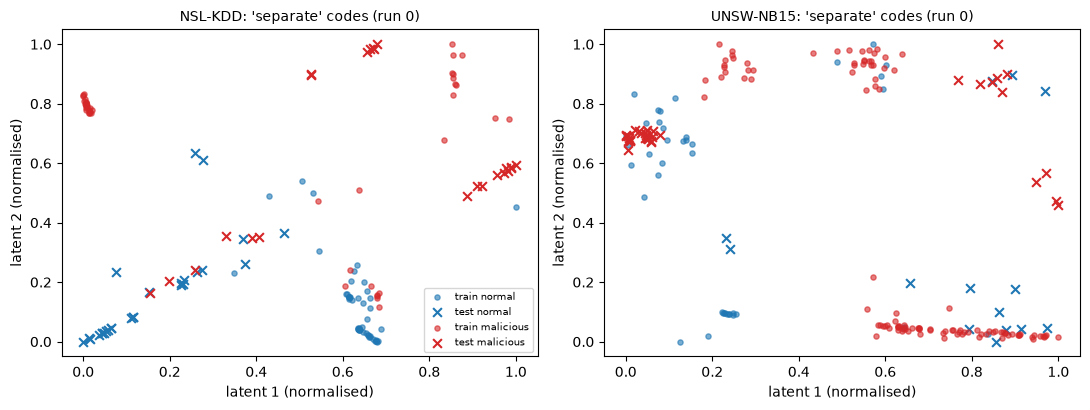

,dataset,protocol,QSVM as published d2,QSVM as published d3,QSVM as published d4,QSVM as published d5,QSVM tuned d3,RBF-SVM tuned
0,NSL-KDD,pool (headline: one autoencoder fitted on unla...,0.840 +- 0.060,0.800 +- 0.040,0.853 +- 0.046,0.860 +- 0.072,0.860 +- 0.072,0.847 +- 0.012
1,NSL-KDD,train (autoencoder on the training rows only),0.840 +- 0.035,0.840 +- 0.020,0.827 +- 0.031,0.833 +- 0.023,0.840 +- 0.020,0.840 +- 0.020
2,NSL-KDD,separate (paper-like: test codes from their ow...,0.540 +- 0.092,0.587 +- 0.272,0.553 +- 0.272,0.540 +- 0.087,0.507 +- 0.196,0.727 +- 0.196
3,UNSW-NB15,pool (headline: one autoencoder fitted on unla...,0.927 +- 0.023,0.907 +- 0.012,0.887 +- 0.012,0.893 +- 0.012,0.913 +- 0.012,0.927 +- 0.023
4,UNSW-NB15,train (autoencoder on the training rows only),0.927 +- 0.023,0.893 +- 0.012,0.887 +- 0.012,0.873 +- 0.050,0.913 +- 0.023,0.920 +- 0.035
5,UNSW-NB15,separate (paper-like: test codes from their ow...,0.600 +- 0.340,0.587 +- 0.323,0.580 +- 0.303,0.593 +- 0.310,0.600 +- 0.302,0.600 +- 0.340


In [15]:
t0 = time.perf_counter()
for name in DATASETS:
    for mode in ("train", "separate"):
        run_cell(name, HEAD[name], N_QUBITS, mode)
RES = pd.DataFrame(ROWS)
print(f"done in {seconds_since(t0):.0f} s")

fig, axes = plt.subplots(1, len(DATASETS), figsize=(11, 4.2))
for ax, name in zip(axes, DATASETS):
    L = LAT0[(name, HEAD[name], N_QUBITS, "separate")]; tr, te = PART[name]["draws"][0]; y = DS[name]["y"]
    for lab, c, nm in ((0, "tab:blue", "normal"), (1, "tab:red", "malicious")):
        ax.scatter(L["A_train"][y[tr] == lab, 0], L["A_train"][y[tr] == lab, 1], s=14, color=c, alpha=0.6, label=f"train {nm}")
        ax.scatter(L["A_test"][y[te] == lab, 0], L["A_test"][y[te] == lab, 1], s=40, color=c, marker="x", label=f"test {nm}")
    ax.set_title(f"{name}: 'separate' codes (run 0)", fontsize=10); ax.set_xlabel("latent 1 (normalised)"); ax.set_ylabel("latent 2 (normalised)")
axes[0].legend(fontsize=7)
plt.tight_layout(); plt.show()

rows = []
for name in DATASETS:
    for mode, label in (("pool", "pool (headline: one autoencoder fitted on unlabelled pool)"), ("train", "train (autoencoder on the training rows only)"),
                        ("separate", "separate (paper-like: test codes from their own autoencoder; diagnostic)")):
        d = RES[(RES.dataset == name) & (RES.activation == HEAD[name]) & (RES.dim == N_QUBITS) & (RES["mode"] == mode)]
        row = dict(dataset=name, protocol=label)
        for dp in (2, 3, 4, 5):
            row[f"QSVM as published d{dp}"] = ms(pick(d, model="QSVM", depth=float(dp), variant="as published").accuracy)
        row["QSVM tuned d3"] = ms(pick(d, model="QSVM", depth=3.0, variant="tuned").accuracy)
        row["RBF-SVM tuned"] = ms(pick(d, model="RBF-SVM tuned").accuracy)
        rows.append(row)
display(pd.DataFrame(rows))

## 9. Paper versus this notebook

Each row is one number of the paper. The verdict is **reproduced** when our value is within `TOL = 0.02` of the paper's (two
accuracy points; with 50 test connections that is one connection), **exceeded** / **not reached** when it is more than 0.02
above / below, and **cannot be checked** when the quantity is not defined well enough or needs hardware that the paper did
not use either. For the accuracy tables the notebook value is the mean over the `N_RUNS` draws for the headline activation; the
paper reports one draw, so run 0 and the std are shown too. "As published" (bandwidth 1, `C = 1`) is the primary comparison; the
tuned QSVM is shown for reference. The classical SVM of Table II is compared with the RBF-SVM trained on the large pool.
Qualitative claims are checked by the sign and size of the gaps stated in each row.

In [16]:
def verdict(paper, ours, tol=TOL):
    if ours is None or (isinstance(ours, float) and np.isnan(ours)):
        return "cannot be checked"
    return "reproduced" if abs(ours - paper) <= tol else ("exceeded" if ours > paper else "not reached")

def acc_stats(name, depth, variant, act=None, mode="pool", dim=N_QUBITS):
    d = RES[(RES.dataset == name) & (RES.activation == (act or HEAD[name])) & (RES.dim == dim) & (RES["mode"] == mode)]
    g = pick(d, model="QSVM", depth=float(depth), variant=variant).accuracy
    return float(g.mean()), float(g[pick(d, model="QSVM", depth=float(depth), variant=variant).run == 0].iloc[0]), float(g.std(ddof=1)) if len(g) > 1 else 0.0

rows = []
for name in DATASETS:
    for dp in DEPTHS:
        m, r0, sd = acc_stats(name, dp, "as published"); mt, r0t, sdt = acc_stats(name, dp, "tuned")
        rows.append(dict(claim=f"Table I: {name} QSVM accuracy, depth {dp}", paper=PAPER_T1[name][dp], notebook_mean=round(m, 3), notebook_std=round(sd, 3), notebook_run0=round(r0, 3),
                         verdict=verdict(PAPER_T1[name][dp], m), tuned_mean=round(mt, 3), verdict_tuned=verdict(PAPER_T1[name][dp], mt)))
for name in DATASETS:
    b = BIG[(name, HEAD[name])]
    rows.append(dict(claim=f"Table II: {name} classical SVM accuracy (liquidSVM, entire dataset) vs RBF-SVM on {b['n_train']:,} connections", paper=PAPER_T2[name][0],
                     notebook_mean=round(b["accuracy"], 3), notebook_std=np.nan, notebook_run0=round(b["accuracy"], 3), verdict=verdict(PAPER_T2[name][0], b["accuracy"])))
    rows.append(dict(claim=f"Table II: {name} liquidSVM positive / negative validation error (ours: miss rate {b['fnr']:.3f} / false-alarm rate {b['fpr']:.3f})",
                     paper=f"{PAPER_T2[name][1]} / {PAPER_T2[name][2]}", notebook_mean=np.nan, notebook_std=np.nan, notebook_run0=np.nan,
                     verdict="cannot be checked (liquidSVM's error definition and class coding are not given)"))

def mean_acc(name, depths, variant, **kw):
    return float(np.mean([acc_stats(name, dp, variant, **kw)[0] for dp in depths]))
def same_input(name, model, act=None):
    d = RES[(RES.dataset == name) & (RES.activation == (act or HEAD[name])) & (RES.dim == N_QUBITS) & (RES["mode"] == "pool")]
    return float(pick(d, model=model).accuracy.mean())

claims = []
for name in DATASETS:
    rise = acc_stats(name, 5, "as published")[0] - acc_stats(name, 2, "as published")[0]
    claims.append((f"Fig. 8 / Table I: {name} accuracy rises with depth (depth 5 minus depth 2, paper {PAPER_T1[name][5] - PAPER_T1[name][2]:+.2f})", rise,
                   "reproduced" if rise >= TOL else "not reached"))
    sat = acc_stats(name, 5, "as published")[0] - acc_stats(name, 3, "as published")[0]
    claims.append((f"Table I: {name} accuracy saturates after depth 3 (depth 5 minus depth 3, paper +0.00)", sat, "reproduced" if abs(sat) <= TOL else ("exceeded" if sat > 0 else "not reached")))
gap_n = mean_acc("NSL-KDD", (3, 4, 5), "as published") - BIG[("NSL-KDD", HEAD["NSL-KDD"])]["accuracy"]
claims.append(("Sec. IV: NSL-KDD QSVM 'very close' to the classical SVM (QSVM depth 3-5 minus large-pool SVM, paper -0.01)", gap_n, "reproduced" if abs(gap_n) <= TOL else ("exceeded" if gap_n > 0 else "not reached")))
gap_u = mean_acc("UNSW-NB15", (3, 4, 5), "as published") - BIG[("UNSW-NB15", HEAD["UNSW-NB15"])]["accuracy"]
claims.append(("Sec. IV: UNSW-NB15 QSVM 'somewhat lower' than the classical SVM (QSVM depth 3-5 minus large-pool SVM, paper -0.11)", gap_u, "reproduced" if gap_u <= -TOL else "not reached"))
dd = mean_acc("NSL-KDD", (3, 4, 5), "as published") - mean_acc("UNSW-NB15", (3, 4, 5), "as published")
claims.append(("Sec. IV: the result depends on the dataset (NSL-KDD QSVM minus UNSW-NB15 QSVM, paper +0.28)", dd, "reproduced" if dd >= TOL else "not reached"))
for name in DATASETS:
    adv = mean_acc(name, (3, 4, 5), "tuned") - same_input(name, "RBF-SVM tuned")
    claims.append((f"Sec. V: 'hint of quantum advantage' on {name} (tuned QSVM depth 3-5 minus tuned RBF-SVM on the same small sample; positive = QSVM ahead)", adv,
                   "reproduced" if adv >= TOL else "not reached"))
for name in DATASETS:
    accs = [acc_stats(name, dp, "as published")[0] for dp in DEPTHS]; ktas = [KTA[(name, dp)] for dp in DEPTHS]
    rk = float(np.corrcoef(accs, ktas)[0, 1]) if np.std(accs) > 0 and np.std(ktas) > 0 else float("nan")
    claims.append((f"Figs. 9 / 10: {name} a more distinctive kernel goes with higher accuracy (Pearson r between kernel-target alignment and accuracy over depths 2-5)", rk,
                   "cannot be checked" if np.isnan(rk) else ("reproduced" if rk > 0 else "not reached")))
for name in DATASETS:
    sep = acc_stats(name, 3, "as published", mode="separate")[0] - acc_stats(name, 3, "as published")[0]
    claims.append((f"Figs. 4 / 7: {name} test codes from a separately fitted autoencoder do not match the training codes (accuracy 'separate' minus 'pool', depth 3)", sep,
                   "reproduced" if sep <= -TOL else "not reached"))
for text, val, v in claims:
    rows.append(dict(claim=text, paper="(qualitative)", notebook_mean=round(val, 3), notebook_std=np.nan, notebook_run0=np.nan, verdict=v))
rows.append(dict(claim="Figs. 3-7: autoencoder training losses 9.4375 / 9.3450 / 9.3377 / 9.4114 / 8.2805", paper="9.3-9.4 (NSL-KDD), 8.28 (UNSW-NB15)", notebook_mean=np.nan, notebook_std=np.nan,
                 notebook_run0=np.nan, verdict="cannot be checked (Ruta's loss normalisation and data scaling are not given; our reconstruction errors are printed in Section 3)"))
rows.append(dict(claim="IBM QX hardware", paper="none: 'IBM QX in simulation mode'", notebook_mean=np.nan, notebook_std=np.nan, notebook_run0=np.nan,
                 verdict="cannot be checked (the paper reports no hardware result)"))
comparison = pd.DataFrame(rows)
display(comparison)
counts = comparison.verdict.str.split(" \(").str[0].value_counts()
print("verdict counts:", counts.to_dict())
primary = comparison[comparison.claim.str.startswith("Table I: ") & comparison.claim.str.contains("QSVM accuracy, depth")]
print("Table I (as published), reproduced:", int((primary.verdict == "reproduced").sum()), "of", len(primary), "| tuned QSVM:", int((primary.verdict_tuned == "reproduced").sum()), "of", len(primary))
print(f"total notebook time {seconds_since(NOTEBOOK_T0) / 60:.1f} min")

,claim,paper,notebook_mean,notebook_std,notebook_run0,verdict,tuned_mean,verdict_tuned
0,"Table I: NSL-KDD QSVM accuracy, depth 2",0.8,0.840,0.060,0.840,exceeded,0.853,exceeded
1,"Table I: NSL-KDD QSVM accuracy, depth 3",0.92,0.800,0.040,0.840,not reached,0.860,not reached
2,"Table I: NSL-KDD QSVM accuracy, depth 4",0.92,0.853,0.046,0.880,not reached,0.853,not reached
3,"Table I: NSL-KDD QSVM accuracy, depth 5",0.92,0.860,0.072,0.940,not reached,0.873,not reached
4,"Table I: UNSW-NB15 QSVM accuracy, depth 2",0.6,0.927,0.023,0.940,exceeded,0.927,exceeded
5,"Table I: UNSW-NB15 QSVM accuracy, depth 3",0.64,0.907,0.012,0.920,exceeded,0.913,exceeded
6,"Table I: UNSW-NB15 QSVM accuracy, depth 4",0.64,0.887,0.012,0.900,exceeded,0.913,exceeded
7,"Table I: UNSW-NB15 QSVM accuracy, depth 5",0.64,0.893,0.012,0.900,exceeded,0.900,exceeded
8,Table II: NSL-KDD classical SVM accuracy (liqu...,0.93,0.934,NaN,0.934,reproduced,NaN,NaN
9,Table II: NSL-KDD liquidSVM positive / negativ...,0.136 / 0.019,NaN,NaN,NaN,cannot be checked (liquidSVM's error definitio...,NaN,NaN


verdict counts: {'not reached': 9, 'exceeded': 7, 'reproduced': 7, 'cannot be checked': 4}
Table I (as published), reproduced: 0 of 8 | tuned QSVM: 0 of 8
total notebook time 21.5 min


## Reading the paper critically

**Fifty test connections cannot rank anything.** One connection is two accuracy points. The paper's headline difference
between the QSVM (0.92) and the classical SVM (0.93) is half a connection of test data; the step from depth 2 to depth 3 on
NSL-KDD (0.80 to 0.92) is six connections. The three draws of the FAST run of this notebook already show a standard deviation
of up to seven points for the same method on NSL-KDD (depths 2 to 5, as published: 0.84, 0.80, 0.85, 0.86 with std 0.04 to
0.07), so a single draw cannot support statements such as "accuracy increases with the quantum circuit depth as theoretically
foreseen". In our draws the NSL-KDD curve is flat within that noise and on UNSW-NB15 depth 2 is the best (0.93, then 0.91, 0.89,
0.89).

**The quantum and the classical numbers are not like for like.** The QSVM is trained on 100 (150) connections, while the
classical liquidSVM of Table II is trained "over the entire dataset" (tens of thousands of connections). The right control is the
same classical SVM on the same 100 (150) codes, which this notebook reports in every table. In our draws a tuned RBF-SVM on the
two latent numbers is on par with the kernel: on NSL-KDD the tuned QSVM is 0.6 to 2.6 points ahead of it (0.847), less than one
standard deviation; on UNSW-NB15 the RBF-SVM (0.927) is 0 to 2.7 points ahead of the tuned QSVM. The paper's closing remark that
the data "hint at an advantage for the quantum processing" is therefore not supported by its own numbers (0.92 < 0.93 and
0.64 < 0.75), and not by ours.

**Dimensionality reduction decides the result.** The kernel only sees two numbers per connection. Whatever separates normal
from malicious traffic must survive the squeeze through a two-unit autoencoder. In our runs the four activations (Linear / tanh
/ ReLU / Sigmoid) differ by at most five points at any depth, which is inside the draw-to-draw noise; the exception is
ReLU, whose autoencoder lost one of its two latent units (constant code, reconstruction error 1.41 against 0.82) and with it
the large-pool classical SVM (0.894 against 0.934 to 0.939). A linear autoencoder spans, at its optimum, the same subspace as PCA.

**The UNSW-NB15 numbers of the paper are below what the data supports.** The paper's QSVM accuracies (0.60 to 0.64) and its
classical SVM (0.75) are not above the majority-class rate (the training partition is 68 % attacks; the majority-class rule
scores 0.72 on our draws), whereas the same pipeline here reaches 0.89 to 0.93 with the QSVM and 0.93 with the RBF-SVM on a large
pool. Heavy-tailed UNSW-NB15 features (bytes, packets, loads) make plain min-max scaling a poor choice, but it does not explain
a gap of this size; the sampling scheme, the exact file or the autoencoder settings of the paper must differ in ways the text does
not reveal.

**The test-set mismatch is an artefact of the protocol.** Figures 4 and 7 show that the test codes do not follow the training
codes. Two autoencoders trained separately are two unrelated coordinate systems (rotation, sign flips, different scales), so
this is what should be expected and says nothing about the data. Section 8 reproduces it; the fix is to fit the encoder once and
apply it to new traffic. (In the paper the consequence was that the official test files were not used at all, so none of the
reported numbers is on a standard held-out test set.)

**Inconsistencies in the text.** Section IV-C describes amplitude encoding, an SU(4) unitary, a $Z_1Z_2$ parity measurement and
layers of rotation gates with controlled-Pauli entanglers: that is a variational classifier, not the Havlicek QSVM whose results
are reported; the introduction announces "unsupervised QML" although the SVM is supervised and uses labels; the caption of
Fig. 3 mentions Linear and Elu while the panels say sigmoid and hyperbolic tangent; the "positive / negative validation error" of
Table II are never defined. The latent size, the number of qubits, the sampling scheme and the activation function behind
Table I are not stated, so an exact reproduction is impossible; this notebook documents each choice.

**Everything is simulation.** The abstract says "IBM QX in simulation mode"; no hardware was used. On real devices a kernel
over 100 points needs 5,000 circuits per training matrix, each estimated from a finite number of shots, which the paper
does not discuss.

## Exercises

1. **Qubits.** Set `FAST_MODE = False` (or `EXTRA_DIMS = [3, 4]`) and compare the accuracy at 2, 3 and 4 qubits. Does a larger
   latent code help the quantum kernel or the RBF-SVM more?
2. **Bandwidth.** Print the mean off-diagonal value of the training kernel for bandwidth 1 and `math.pi` at depth 5. Why does a
   larger angle make the kernel matrix look like the identity, and what does that do to the test accuracy?
3. **Entanglement.** Change `ENTANGLEMENT` to `"linear"` and use `N_QUBITS = 4`. Does the kernel-target alignment of Section 6
   change more than the draw-to-draw spread?
4. **A fair autoencoder.** Replace the 2-unit autoencoder by `PCA(n_components=2)` fitted on the pool. Which activation of
   Section 3 is closest to it, and why does the linear autoencoder give nearly the same accuracy?
5. **Shot noise.** Replace the exact kernel by a finite-shot estimate (`np.random.binomial(1024, K) / 1024`, symmetrised, with a
   unit diagonal) and look at how the accuracy of the depth-5 QSVM changes with 100, 1,024 and 10,000 shots. Is the noisy matrix
   still positive semi-definite? What does `SVC` do with it?